# Edits Data Analysis

In the first half of this notebook, we will slice and dice data to figure out what we want to annotate and how, and also filter out our data. In the second half of this notebook, we will look at the filtered data and look for patterns as a whole, by model, by various subsets, and more. 

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import Levenshtein
import code_bert_score
import json
import numpy as np
import scipy.stats as stats
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import mannwhitneyu
import re
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from openai import OpenAI

In [2]:
data_folder = "./data"
# data_folder = "./data/edits_dataset_sep29"
# data_folder = "/data/group_data/code_edits"

## Load Data

In [ ]:
user_ids = json.load(open(f"{data_folder}/user_ids.json", "r"))
num_batches = len(user_ids)
total_users = num_batches * 30  # each batch has 30 users
print(f"Total number of users: {total_users}")

Total number of users: 4110


In [4]:
datasets = []
for i in range(num_batches):
    df = pd.read_csv(f"{data_folder}/dataset_batch{i}.csv")
    datasets.append(df)
dataset_df = pd.concat(datasets, ignore_index=True)

# size of 77980 -> size of 53614
dataset_df = dataset_df[(dataset_df["codebert_score"] > 0.68) | (dataset_df["codebert_score"] == 0)]

print("Dataset length:", len(dataset_df))
print(dataset_df.columns)

Dataset length: 53614
Index(['outcome_pair_completion_id', 'outcome_pair_id',
       'outcome_completion_id', 'outcome', 'outcome_snippet',
       'outcome_full_snippet', 'outcome_timestamp', 'outcome_full_file',
       'outcome_snippet_start_line', 'outcome_snippet_end_line',
       'edit_completion_id', 'edit_snippet', 'edit_full_file',
       'edit_timestamp', 'edit_full_snippet', 'all_changed_lines',
       'is_outcome', 'user_id', 'model', 'codebert_score',
       'outcome_context_and_removed_lines', 'edit_snippet_with_extra_context'],
      dtype='object')


In [5]:
outcomes = []
for i in range(num_batches):
    df = pd.read_csv(f"{data_folder}/outcomes_batch{i}.csv")
    outcomes.append(df)
outcomes_df = pd.concat(outcomes, ignore_index=True)

print(f"Total number of outcomes: {len(outcomes_df)}")
print(outcomes_df.columns)

Total number of outcomes: 40149
Index(['version', 'fileType', 'versionBackend', 'userId', 'privacy',
       'acceptedIndex', 'pairId', 'completionItems', 'timestamp', 'collection',
       'repoUrl', 'pairCompletionId', 'model', 'completionId', 'pairIndex',
       'filetype', 'username'],
      dtype='object')


In [6]:
num_trajectories = len(dataset_df["outcome_completion_id"].unique())

print("Number of trajectories:", num_trajectories)
print(f"So, {num_trajectories*100/len(outcomes_df)}% of outcomes have a trajectory associated with it (shortlisted by lang, models, etc)")

Number of trajectories: 5831
So, 14.523400333756756% of outcomes have a trajectory associated with it (shortlisted by lang, models, etc)


In [7]:
dataset_df = dataset_df.merge(
    outcomes_df[['pairId', 'fileType']],
    left_on='outcome_pair_id',
    right_on='pairId',
    how='left'
)
dataset_df = dataset_df.drop(columns=['pairId'])
print("Total number of edits by language:")
dataset_df['fileType'].value_counts().head()

Total number of edits by language:


fileType
python        40390
javascript     7993
typescript     5231
Name: count, dtype: int64

In [8]:
# Note: this is for outcomes, not for the dataset! 
filetype_counts = outcomes_df['fileType'].value_counts()
filetype_counts.head()

fileType
python             17551
javascript          2989
typescript          2133
typescriptreact     2076
html                1573
Name: count, dtype: int64

Total unique Research users (Python/JS/TS): 2058

Users with 0 trajectories: 917
Median number of trajectories per user: 2.00


/var/folders/4x/7d911frs7gddl0f4x7jmbr040000gn/T/ipykernel_90135/2310501849.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = all_counts.groupby(binned).sum().reindex(labels, fill_value=0)


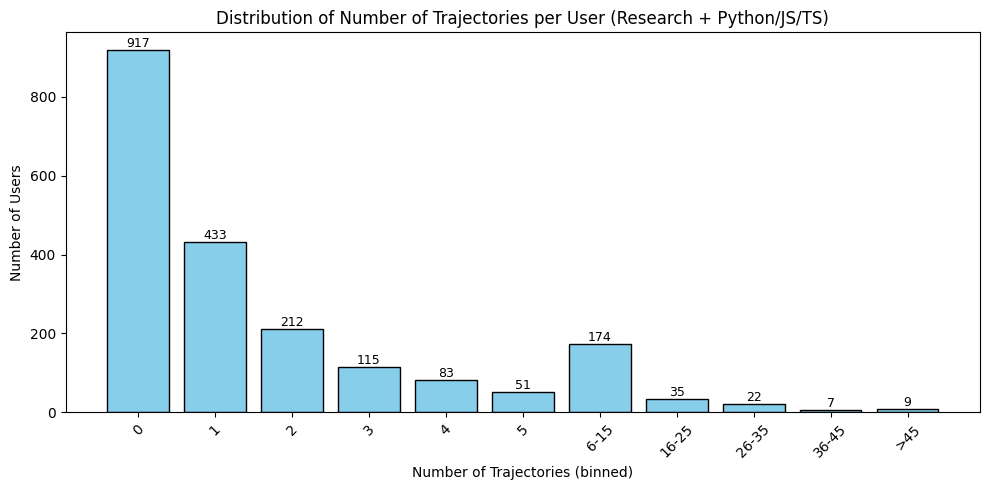

In [9]:
# see number of trajectories per user once we filter for:
# 1. research mode
# 2. languages: python, javascript, typescript

research_lang_user_ids = outcomes_df.loc[
    (outcomes_df["privacy"] == "Research") & (outcomes_df["fileType"].isin(["python", "javascript", "typescript"])),
    "userId"
].unique()
print(f"Total unique Research users (Python/JS/TS): {len(research_lang_user_ids)}")

research_lang_dataset_df = dataset_df[dataset_df["user_id"].isin(research_lang_user_ids)]
user_counts_per_filetype = (
    outcomes_df[
        (outcomes_df["userId"].isin(research_lang_user_ids)) &
        (outcomes_df["fileType"].isin(["python", "javascript", "typescript"]))
    ]
    .groupby("fileType")["userId"]
    .nunique()
    .sort_values(ascending=False)
)

trajectories_per_user = research_lang_dataset_df.groupby("user_id")["outcome_completion_id"].nunique()
users_with_data = len(trajectories_per_user)
zero_users = len(research_lang_user_ids) - users_with_data
print(f"\nUsers with 0 trajectories: {zero_users}")

all_counts = trajectories_per_user.value_counts().sort_index()
if zero_users > 0:
    all_counts.loc[0] = zero_users
all_counts = all_counts.sort_index()

bins = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 15.5, 25.5, 35.5, 45.5, trajectories_per_user.max() + 0.5]
labels = ["0", "1", "2", "3", "4", "5", "6-15", "16-25", "26-35", "36-45", f">{45}"]

binned = pd.cut(all_counts.index, bins=bins, labels=labels)
counts = all_counts.groupby(binned).sum().reindex(labels, fill_value=0)

plt.figure(figsize=(10,5))
bars = plt.bar(counts.index.astype(str), counts.values, width=0.8, color="skyblue", edgecolor="black")
plt.title("Distribution of Number of Trajectories per User (Research + Python/JS/TS)")
plt.xlabel("Number of Trajectories (binned)")
plt.ylabel("Number of Users")
plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height)}",
        ha="center", va="bottom", fontsize=9
    )

median_trajectories = trajectories_per_user.median()
print(f"Median number of trajectories per user: {median_trajectories:.2f}")

plt.tight_layout()
plt.show()

In [10]:
dataset_df["outcome_full_snippet"] = dataset_df["outcome_full_snippet"].fillna("")
dataset_df["edit_full_snippet"] = dataset_df["edit_full_snippet"].fillna("")
dataset_df["edit_snippet"] = dataset_df["edit_snippet"].fillna("")
dataset_df["time_since_completion"] = dataset_df["edit_timestamp"] - dataset_df["outcome_timestamp"]
dataset_df['edit_timestamp_readable'] = pd.to_datetime(dataset_df['edit_timestamp'], unit='s')

In [76]:
unique_edits = dataset_df.drop_duplicates(subset='edit_completion_id')

edit_loc_sum = unique_edits['edit_full_snippet'].astype(str).str.count('\n').add(1).sum()

print(edit_loc_sum)

772230


## Data Processing

In [11]:
def percent_remaining(outcome, snippet):
    ops = Levenshtein.editops(outcome, snippet)    
    num_ops_in_outcome = sum(1 for op, _, _ in ops if op in ('delete', 'replace'))
    assert(num_ops_in_outcome <= len(outcome))

    if outcome == "":
        res = 0.0
    else:
        res = (len(outcome) - (num_ops_in_outcome * 1.0)) / len(outcome)
        assert(res <= 1.0)
    return res

dataset_df["percent_remaining"] = dataset_df.fillna("").apply(
    lambda row: percent_remaining(row["outcome"], row["edit_full_snippet"]), axis=1
)

In [12]:
def percent_added(outcome, snippet):
    ops = Levenshtein.editops(outcome, snippet)
    num_inserts_in_snippet = sum(1 for op, _, _ in ops if op in ('insert'))
    assert(num_inserts_in_snippet <= len(snippet))

    if snippet == "":
        res = 0.0
    else:
        res = (num_inserts_in_snippet * 1.0) / len(snippet)
        assert(res <= 1.0)
    return res

dataset_df["percent_added"] = dataset_df.fillna("").apply(
    lambda row: percent_added(row["outcome"], row["edit_full_snippet"]), axis=1
)

In [13]:
def chars_added(outcome, snippet):
    ops = Levenshtein.editops(outcome, snippet)
    num_inserts_in_snippet = sum(1 for op, _, _ in ops if op in ('insert'))
    assert(num_inserts_in_snippet <= len(snippet))
    
    return num_inserts_in_snippet

dataset_df["chars_added"] = dataset_df.fillna("").apply(
    lambda row: chars_added(row["outcome"], row["edit_full_snippet"]), axis=1
)

In [14]:
# scores = code_bert_score.score(
#     cands=dataset_df["outcome_full_snippet"].tolist(), 
#     refs=dataset_df["edit_full_snippet"].tolist(), 
#     lang="python" # CHANGE
# )
# dataset_df["semantic_similarity"] = scores[3].tolist()

In [15]:
def get_trajectory_durations(df):
    # Sort dataset by timestamp
    dataset_sorted = df.sort_values("edit_timestamp")
    
    # Compute the last edit time per trajectory
    durations = (
        dataset_sorted.groupby("outcome_pair_id")
        .agg(duration=("edit_timestamp", lambda x: x.max()))  # last edit time
        .reset_index()
    )
    
    # Merge in the start (outcome_timestamp) for each trajectory
    durations = durations.merge(
        dataset_df[["outcome_pair_id", "outcome_timestamp"]].drop_duplicates("outcome_pair_id"),
        on="outcome_pair_id"
    )
    
    # Compute the duration in seconds as a plain number
    durations["duration_seconds"] = durations["duration"] - durations["outcome_timestamp"]
    
    avg_duration = durations["duration_seconds"].mean()
    med_duration = durations["duration_seconds"].median()
    print("Mean duration:", avg_duration)
    print("Median duration:", med_duration)

    return durations

In [16]:
def get_trajectory_last_row(df, metric="percent_remaining"):
    # Sort dataset by timestamp
    dataset_sorted = df.sort_values("edit_timestamp")
    
    # Take the last row per outcome_pair_id
    last_rows = dataset_sorted.groupby("outcome_pair_id").tail(1)
    
    # Compute average code_remaining across these last rows
    avg_metric = last_rows[metric].mean()
    med_metric = last_rows[metric].median()
    print("Average " + metric + ":", avg_metric)
    print("Median " + metric + ":", med_metric)

    return last_rows

In [17]:
dataset_df["outcome_length"] = dataset_df["outcome"].fillna("").apply(len)

In [18]:
# Count lines safely (treat NaN as 0 lines)
snippets = dataset_df['outcome_snippet'].fillna('')
snippet_lines = snippets.str.count(r'\n').add(1).where(snippets.ne(''), 0)

# Add line count column
dataset_df["outcome_line_count"] = snippet_lines

## Code Remainder in Edit

Threshold for top 99% longest prefix+suffix: 689.0


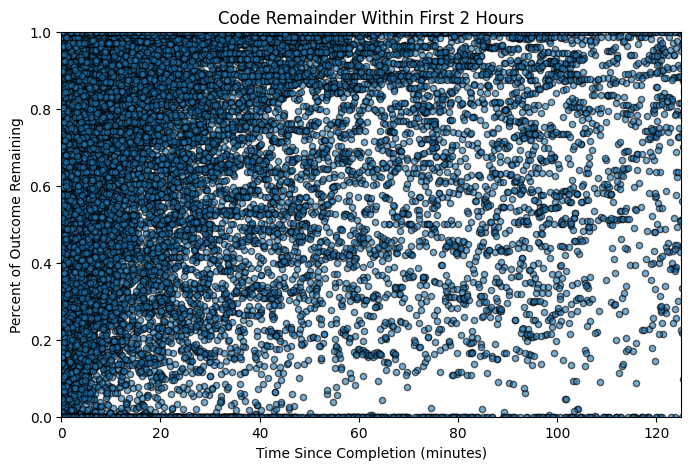

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(
    dataset_df["time_since_completion"] / 60,
    dataset_df["percent_remaining"],
    alpha=0.6,
    s=20,
    edgecolors="k"
)
plt.xlim(0, 7500/60)
plt.ylim(0, 1)
plt.xlabel("Time Since Completion (minutes)")
plt.ylabel("Percent of Outcome Remaining")
plt.title("Code Remainder Within First 2 Hours")
plt.show()

### When the edits were made

In [19]:
completion_ids = list(dataset_df["outcome_completion_id"].unique())
times_changes_after_completion = []
for cid in completion_ids:
    trajectories_df = dataset_df[dataset_df["outcome_completion_id"] == cid].reset_index(drop=True).sort_values("edit_timestamp")

    start_snapshot = trajectories_df.loc[0, 'outcome_snippet']
    start_time = trajectories_df.loc[0, 'outcome_timestamp']

    trajectories = [(start_snapshot, start_time)]
    for _, trajectory_row in trajectories_df.iterrows():
        if trajectory_row['edit_timestamp'] > trajectories_df.loc[0, 'outcome_timestamp']:
            snapshot = trajectory_row['edit_snippet']
            timestamp = trajectory_row['edit_timestamp']
            trajectories.append((snapshot, timestamp))

    for i in range(1, len(trajectories)):
        before_snapshot, before_timestamp = trajectories[i - 1]
        after_snapshot, after_timestamp = trajectories[i]

        change = Levenshtein.distance(before_snapshot, after_snapshot)
        time_diff = after_timestamp - before_timestamp
        times_changes_after_completion.append((change, time_diff))

print(f"Threshold for top 98% longest trajectories: {np.percentile(trajectory_counts['count'], 98)}")
plt.show()

Threshold for top 98% longest trajectories: 53.0


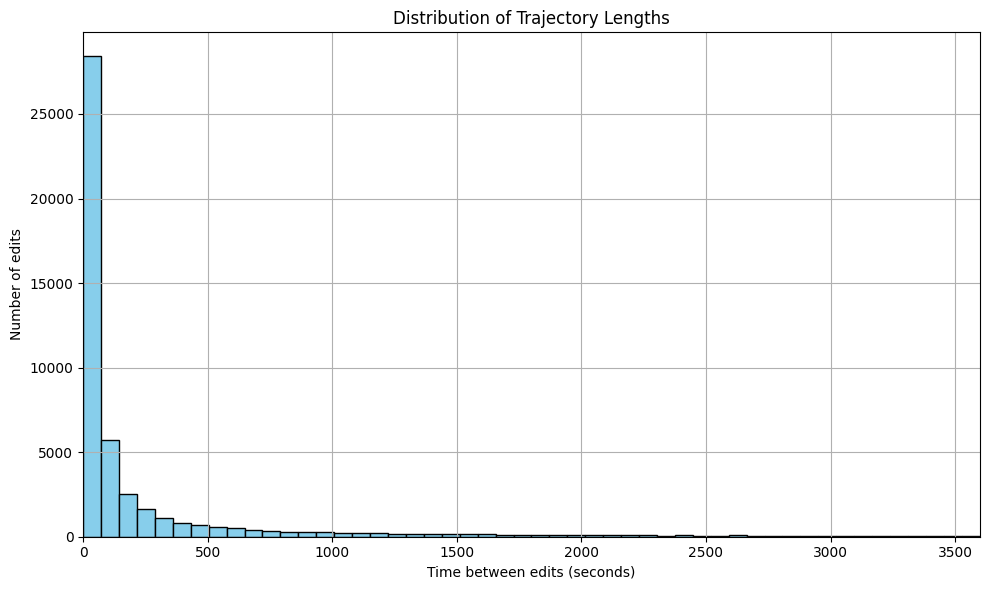

In [57]:
plt.figure(figsize=(10,6))
plt.hist([x[1] for x in times_changes_after_completion if x[1] < 3600], bins=50, color='skyblue', edgecolor='black')
plt.xlabel("Time between edits (seconds)")
plt.ylabel("Number of edits")
plt.title("Distribution of Trajectory Lengths")
plt.grid(True)
plt.tight_layout()
plt.xlim(0, 3600)
plt.show()

In [48]:
# Get a sample of different length trajectories
trajectory_counts = dataset_df.groupby('outcome_completion_id').size().reset_index()
trajectory_counts = trajectory_counts.rename(columns={0: 'count'})

max_count = trajectory_counts['count'].max()
bins = np.arange(0, max_count + 10, 10)  # step=10
trajectory_counts['bin'] = pd.cut(trajectory_counts['count'], bins=bins, right=False)
bin_counts = trajectory_counts.groupby('bin').size()


/var/folders/4x/7d911frs7gddl0f4x7jmbr040000gn/T/ipykernel_20834/4137522330.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = trajectory_counts.groupby('bin').size()


### Length of outcome

NameError: name 'time_diffs_hours' is not defined

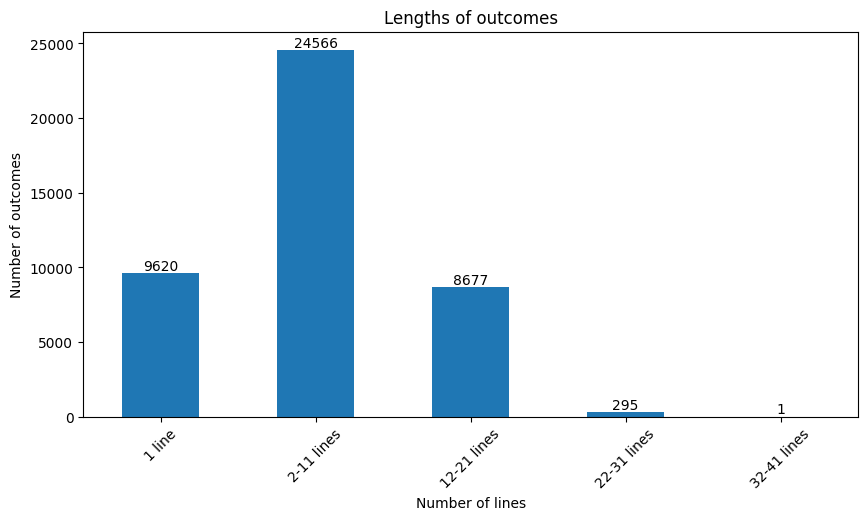

In [20]:
def hours_fmt(x, pos):
    return f"{int(x)}h"

time_js = [td for td, lang in zip(time_diffs_hours, dataset_df['fileType']) if lang == 'javascript']
time_ts = [td for td, lang in zip(time_diffs_hours, dataset_df['fileType']) if lang == 'typescript']
time_py = [td for td, lang in zip(time_diffs_hours, dataset_df['fileType']) if lang == 'python']

bins = np.linspace(min(time_diffs_hours), max(time_diffs_hours), 51)  # 50 bins
counts_js, _ = np.histogram(time_js, bins=bins)
counts_ts, _ = np.histogram(time_ts, bins=bins)
counts_py, _ = np.histogram(time_py, bins=bins)
bin_centers = (bins[:-1] + bins[1:]) / 2
width = (bins[1] - bins[0]) / 3  # bar width

plt.figure(figsize=(12,6))
plt.bar(bin_centers - width/2, counts_js, width=width, color='skyblue', label='JavaScript', edgecolor='black')
plt.bar(bin_centers - width/2, counts_ts, width=width, color='skyblue', label='TypeScript', edgecolor='black')
plt.bar(bin_centers + width/2, counts_py, width=width, color='salmon', label='Python', edgecolor='black')

plt.xlabel("Time after completion (hours)")
plt.ylabel("Number of edits")
plt.title("Distribution of Changes After Completion by Language")
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(hours_fmt))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.xlim(0, 1)
plt.show()

Median time after completion: 0.02 hours


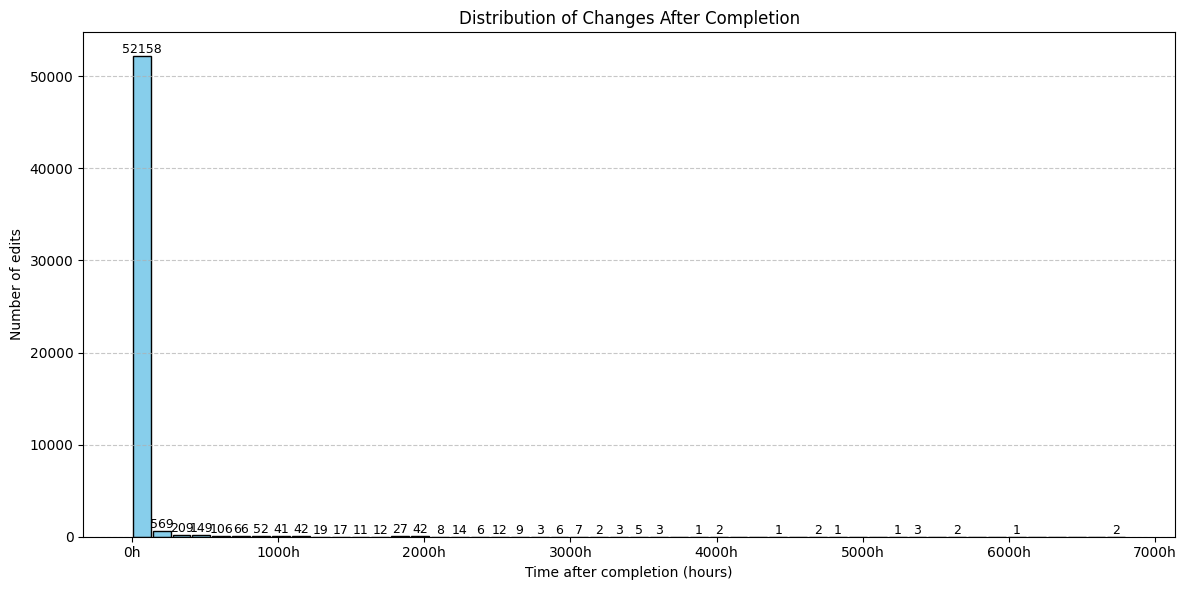

In [21]:
# Single histogram (no language filter)
bins = np.linspace(min(time_diffs_hours), max(time_diffs_hours), 51)  # 50 bins
counts, edges = np.histogram(time_diffs_hours, bins=bins)
bin_centers = (edges[:-1] + edges[1:]) / 2
width = edges[1] - edges[0]

plt.figure(figsize=(12, 6))
bars = plt.bar(bin_centers, counts, width=width * 0.9, color='skyblue', edgecolor='black')

for bar, count in zip(bars, counts):
    if count > 0:
        plt.text(
            bar.get_x() + bar.get_width() / 2, 
            bar.get_height() + 0.2, 
            str(count), 
            ha='center', 
            va='bottom', 
            fontsize=9
        )

median_val = np.median(time_diffs_hours)
print(f"Median time after completion: {median_val:.2f} hours")

plt.xlabel("Time after completion (hours)")
plt.ylabel("Number of edits")
plt.title("Distribution of Changes After Completion")
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(hours_fmt))
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

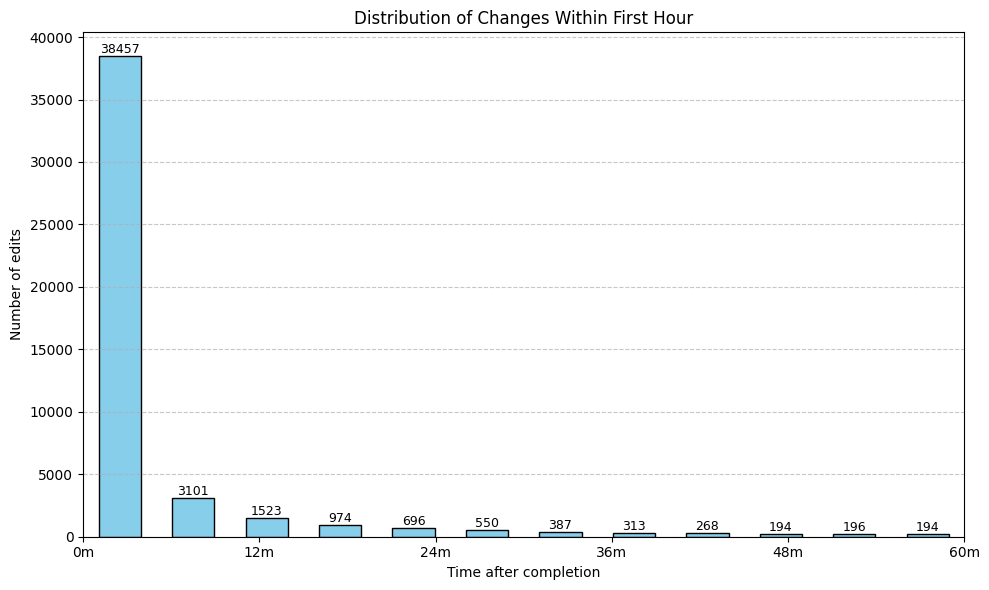

: 

In [ ]:
def minutes_fmt(x, pos):
    return f"{int(x*60)}m"

# Combine all times into one array (no language split)
bins = np.linspace(0, 1, 13)  # 12 bins (each = 5 minutes if range is 0–1 hour)
counts, _ = np.histogram(time_diffs_hours, bins=bins)
bin_centers = (bins[:-1] + bins[1:]) / 2
width = 0.04

plt.figure(figsize=(10, 6))
bars = plt.bar(bin_centers, counts, width=width * 1.2, color='skyblue', edgecolor='black')

# Add count labels above each bar
for bar, count in zip(bars, counts):
    if count > 0:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            str(count),
            ha='center',
            va='bottom',
            fontsize=9
        )

plt.xlabel("Time after completion")
plt.ylabel("Number of edits")
plt.title("Distribution of Changes Within First Hour")
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(minutes_fmt))
plt.xlim(0, 1)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
scores_js = [row["semantic_similarity"] for _, row in dataset_df.iterrows() if row["fileType"] == "javascript"]
times_js  = [row["time_since_completion"] for _, row in dataset_df.iterrows() if row["fileType"] == "javascript"]
scores_ts = [row["semantic_similarity"] for _, row in dataset_df.iterrows() if row["fileType"] == "typescript"]
times_ts  = [row["time_since_completion"] for _, row in dataset_df.iterrows() if row["fileType"] == "typescript"]
scores_py = [row["semantic_similarity"] for _, row in dataset_df.iterrows() if row["fileType"] == "python"]
times_py  = [row["time_since_completion"] for _, row in dataset_df.iterrows() if row["fileType"] == "python"]

minute = list(range(0, 3600, 60))  # every minute
avg_score_js = []
avg_score_ts = []
avg_score_py = []
for i in minute:
    scores_bin_js = [s for s, t in zip(scores_js, times_js) if i <= t < i + 60]
    avg_score_js.append(np.mean(scores_bin_js) if scores_bin_js else 0)
    scores_bin_ts = [s for s, t in zip(scores_ts, times_ts) if i <= t < i + 60]
    avg_score_ts.append(np.mean(scores_bin_ts) if scores_bin_ts else 0)
    scores_bin_py = [s for s, t in zip(scores_py, times_py) if i <= t < i + 60]
    avg_score_py.append(np.mean(scores_bin_py) if scores_bin_py else 0)

plt.figure(figsize=(12, 5))
plt.plot(minute, avg_score_js, marker='o', label='JavaScript', color='skyblue')
plt.plot(minute, avg_score_ts, marker='o', label='TypeScript', color='skyblue')
plt.plot(minute, avg_score_py, marker='o', label='Python', color='salmon')
plt.xlabel("Time Since Completion (seconds)")
plt.ylabel("Mean CodeBERT Score")
plt.title("CodeBERT Score Over Time (Every Minute for the First Hour) by Language")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

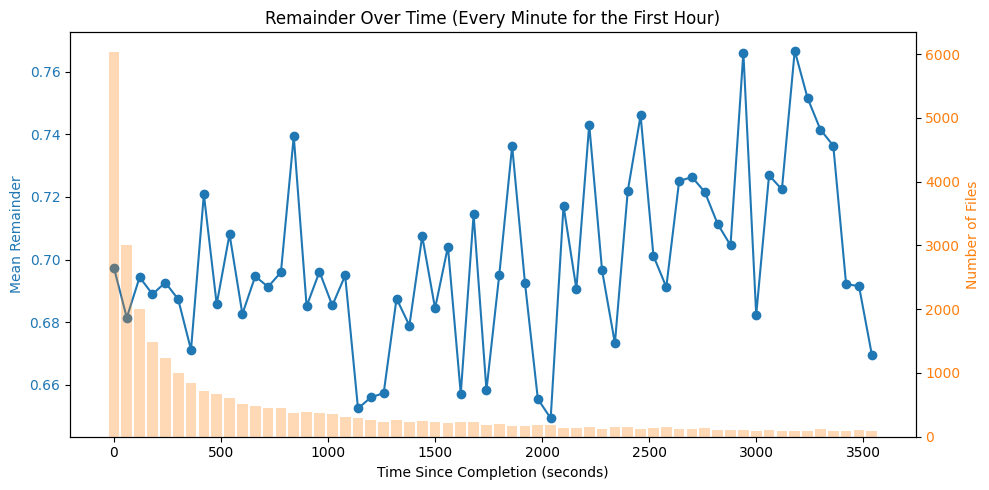

In [21]:
all_remainders = []
all_times = []
for _, row in dataset_df.iterrows():
    all_remainders.append(row["percent_remaining"])
    all_times.append(row["time_since_completion"])

minute = []
avg_remainder = []
counts = []

for i in range(0, 3600, 60):  # each minute in the first hour
    remainders = [r for r, t in zip(all_remainders, all_times) if i <= t < i + 60]
    
    minute.append(i)
    counts.append(len(remainders))
    avg_remainder.append(sum(remainders) / len(remainders) if remainders else 0)

# Plot mean remainder (line) + counts (bar on secondary y-axis)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel("Time Since Completion (seconds)")
ax1.set_ylabel("Mean Remainder", color=color)
ax1.plot(minute, avg_remainder, marker='o', color=color, label="Mean Remainder")
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel("Number of Files", color=color)
ax2.bar(minute, counts, width=50, alpha=0.3, color=color, label="Edits/snapshots Count")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Remainder Over Time (Every Minute for the First Hour)")
fig.tight_layout()
plt.show()

Average percent_remaining: 0.5554477023172044
Median percent_remaining: 0.6287683031869078


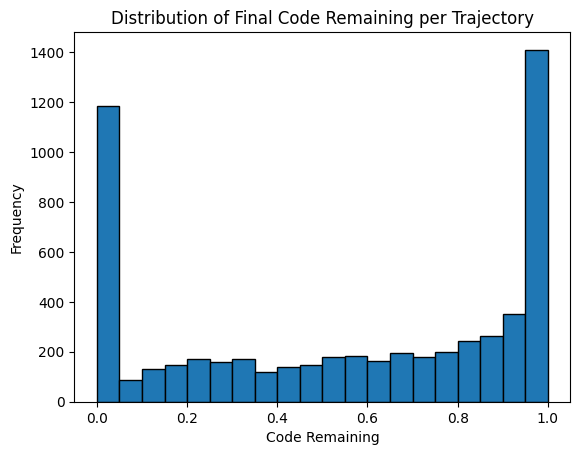

In [22]:
# Get the amount of code remaining at the end of each trajectory

last_rows = get_trajectory_last_row(dataset_df)

plt.hist(last_rows["percent_remaining"], bins=20, edgecolor="black")
plt.xlabel("Code Remaining")
plt.ylabel("Frequency")
plt.title("Distribution of Final Code Remaining per Trajectory")
plt.show()

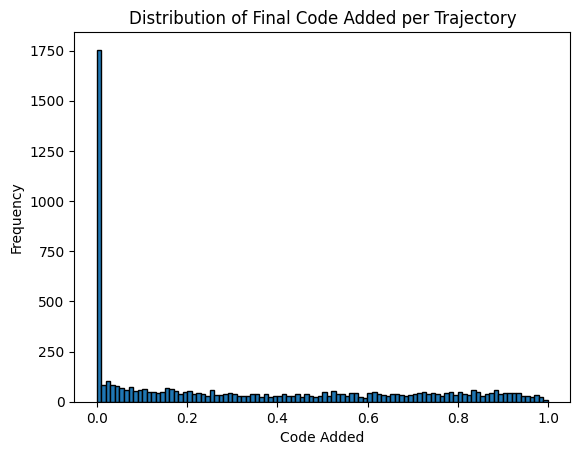

Average code added: 0.31872391154058727


In [23]:
# Get the amount of code remaining at the end of each trajectory

# Sort dataset by timestamp
dataset_sorted = dataset_df.sort_values("edit_timestamp")

# Take the last row per outcome_pair_id
last_rows = dataset_sorted.groupby("outcome_pair_id").tail(1)

plt.hist(last_rows["percent_added"], bins=100, edgecolor="black")
plt.xlabel("Code Added")
plt.ylabel("Frequency")
plt.title("Distribution of Final Code Added per Trajectory")
plt.show()

# Compute average code_remaining across these last rows
avg_code_added = last_rows["percent_added"].mean()

print("Average code added:", avg_code_added)

In [20]:
# Get the amount of changes made to each trajectory
all_distances = []
all_times = []
changes = []

for pair_id in dataset_df["outcome_pair_id"].unique():
    trajectory_df = dataset_df[dataset_df["outcome_pair_id"] == pair_id]
    trajectory_df = trajectory_df.sort_values("edit_timestamp")

    # Compute Levenshtein distances between consecutive edits
    lev_distances = [0]  # First edit has no "prior" to compare to

    prior_snippet = trajectory_df["edit_full_snippet"].iloc[0]
    for current_snippet in trajectory_df["edit_full_snippet"].iloc[1:]:
        distance = Levenshtein.distance(prior_snippet, current_snippet)
        lev_distances.append(distance)
        prior_snippet = current_snippet  # Move forward

    changes.append(sum(lev_distances))
    
    all_distances += lev_distances
    all_times += trajectory_df["time_since_completion"].tolist()

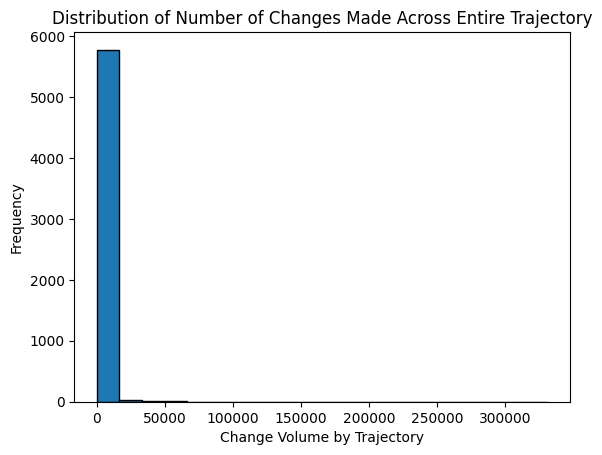

Average change volume: 1278.173010973937


In [25]:
plt.hist(changes, bins=20, edgecolor="black")
plt.xlabel("Change Volume by Trajectory")
plt.ylabel("Frequency")
plt.title("Distribution of Number of Changes Made Across Entire Trajectory")
plt.show()

print("Average change volume:", sum(changes) / len(changes))

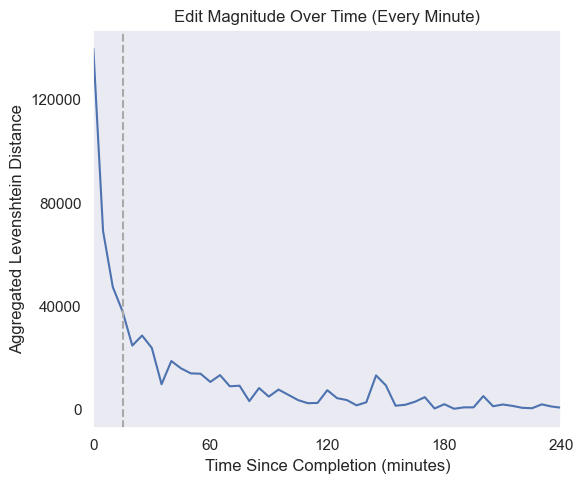

In [32]:
grouped_x = []
grouped_y = []
for i in range(0, 50000, 60):  # step = 60s = 1 minute
    distances = []
    for distance, time in zip(all_distances, all_times):
        if i <= time < i + 60:
            distances.append(distance)
    
    grouped_x.append(i / 60)  # convert seconds → minutes
    grouped_y.append(sum(distances))

# Plot
# plt.figure(figsize=(10, 5))
# plt.plot(grouped_x, grouped_y, marker='o')
# plt.xlabel("Time Since Completion (minutes)")
# plt.ylabel("Aggregated Levenshtein Distance to Previous Version")
# plt.title("Edit Magnitude Over Time (Every Minute)")
# plt.grid(True)
# plt.tight_layout()
# plt.show()

# Optional: nicer default styling
sns.set_theme()

# # Plot
# plt.figure(figsize=(6, 5))
# sns.lineplot(x=grouped_x, y=grouped_y)

# plt.axvline(x=15, linestyle='--', color='#a9a9a9')
# plt.xlim(0, 240)
# # plt.xlim(0, 50)

# plt.xlabel("Time Since Completion (minutes)")
# plt.ylabel("Aggregated Levenshtein Distance")
# plt.title("Edit Magnitude Over Time (Every Minute)")

# plt.grid(True)
# plt.tight_layout()
# plt.show()

plt.figure(figsize=(6, 5))
sns.lineplot(x=grouped_x, y=grouped_y)

plt.axvline(x=15, linestyle='--', color='#a9a9a9')
plt.xlim(0, 240)

ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

plt.xlabel("Time Since Completion (minutes)")
plt.ylabel("Aggregated Levenshtein Distance to Previous Version")
plt.title("Edit Magnitude Over Time (Every Minute)")

plt.grid(False)
plt.tight_layout()
plt.show()

Mean duration: 701539.7933813443
Median duration: 2984.5
75th percentile cutoff: 175798.25


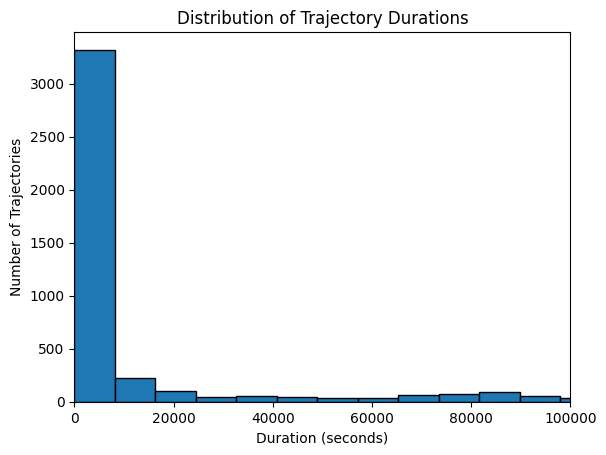

In [27]:
# Get the duration of the trajectories

durations = get_trajectory_durations(dataset_df)

cutoff = durations["duration_seconds"].quantile(0.75)
print("75th percentile cutoff:", cutoff)

below_cutoff_ids = durations.loc[durations["duration_seconds"] <= cutoff, "outcome_pair_id"]

# Plot histogram of durations
plt.hist(durations["duration_seconds"], bins=3000, edgecolor='black')
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Trajectories")
plt.title("Distribution of Trajectory Durations")
plt.xlim(0, 100000)
plt.show()

### Exploratory Mode

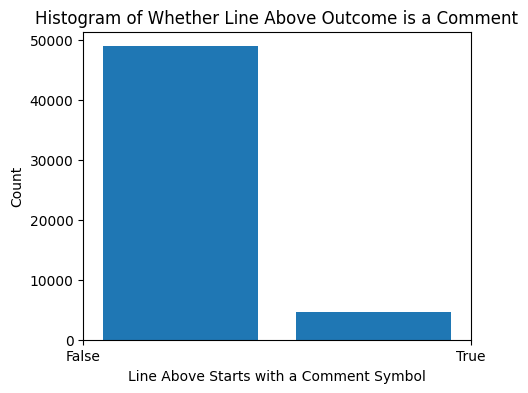

: 

In [ ]:
# Check if the line above is a comment

# Define a helper function
def line_above_starts_with_comment(row):
    try:
        file_content = row["outcome_full_file"].splitlines()
        start_line = int(row["outcome_snippet_start_line"])
        if start_line <= 1:
            return False  # no line above
        line_above = file_content[start_line - 2]  # zero-indexed
        line = line_above.strip()
        has_comment_above = line.startswith("#") or line.startswith("//") or "\"\"\"" in line or line.endswith("*/")
        is_code = False

        # Double check that the edit does not involve commenting out code
        if has_comment_above:
            # Remove comment markers
            if line.startswith("#"):
                line = line[1:].strip()
            elif line.startswith("//"):
                line = line[2:].strip()
            elif line.endswith("*/"):           # <-- must be quoted
                line = line[:-2].strip()        # <-- removing last 2 chars is correct
            else:
                line = line.replace('"""', '').strip()
            
            tokens = line.split()

            # ===== Heuristics for “looks like code” =====
            looks_like_code = False
            
            # 1) Assignments (x = 1, x=1)
            assignment_re = re.compile(r'^[A-Za-z_]\w*(?:[\.\[\]\w]*)\s*=\s*.+$')
            
            # 2) JS-style declarations (const/let/var x = 1;)
            js_decl_re = re.compile(r'^(?:const|let|var)\s+[A-Za-z_$]\w*\s*(?:=|;).*$')
            
            # 3) Python loops
            py_for_re   = re.compile(r'^for\s+.+\s+in\s+.+:\s*$')
            py_while_re = re.compile(r'^while\s+.+:\s*$')
            
            # 4) Function defs (Python/JS)
            func_def_re = re.compile(r'^(?:def|function)\s+[A-Za-z_]\w*\s*\(')
            
            # 5) Calls / indexing / property+call
            call_re   = re.compile(r'^[A-Za-z_]\w*(?:\.[A-Za-z_]\w*)*\s*\(.*\)\s*[;:]?$')  # x(), x.y(), f(...):
            index_re  = re.compile(r'^[A-Za-z_]\w*(?:\.[A-Za-z_]\w*)*\s*\[.*\]\s*[;:]?$')  # x[...], x.y[...]
            return_re = re.compile(r'^return(?:\s+.+)?\s*;?$')
            
            code_patterns = [
                assignment_re, js_decl_re, py_for_re, py_while_re,
                func_def_re, call_re, index_re, return_re
            ]
            
            if any(pat.match(line) for pat in code_patterns):
                is_code = True

        return has_comment_above and not is_code
    except Exception:
        return None

# Apply without modifying dataset_df
line_above_is_comment = dataset_df.apply(line_above_starts_with_comment, axis=1)

# Drop None values for clean plotting
clean_series = line_above_is_comment.dropna()

# Plot histogram (True/False counts)
plt.figure(figsize=(5, 4))
plt.hist(clean_series.astype(int), bins=2, rwidth=0.8)
plt.xticks([0, 1], ["False", "True"])
plt.xlabel("Line Above Starts with a Comment Symbol")
plt.ylabel("Count")
plt.title("Histogram of Whether Line Above Outcome is a Comment")
plt.show()

In [29]:
# filtered_df = dataset_df[dataset_df["outcome_pair_id"].isin(below_cutoff_ids)]
filtered_df = dataset_df

exploratory_mode_df = filtered_df[line_above_is_comment == True]
# Sort dataset by timestamp
dataset_sorted = exploratory_mode_df.sort_values("edit_timestamp")
# Take the last row per outcome_pair_id
exploratory_mode_df = dataset_sorted.groupby("outcome_pair_id").tail(1)

not_exploratory_mode_df = filtered_df[line_above_is_comment == False]
# Sort dataset by timestamp
dataset_sorted = not_exploratory_mode_df.sort_values("edit_timestamp")
# Take the last row per outcome_pair_id
not_exploratory_mode_df = dataset_sorted.groupby("outcome_pair_id").tail(1)

Mean duration: 458769.1406025825
Median duration: 1118.0
Mean duration: 734492.3045764362
Median duration: 3497.0


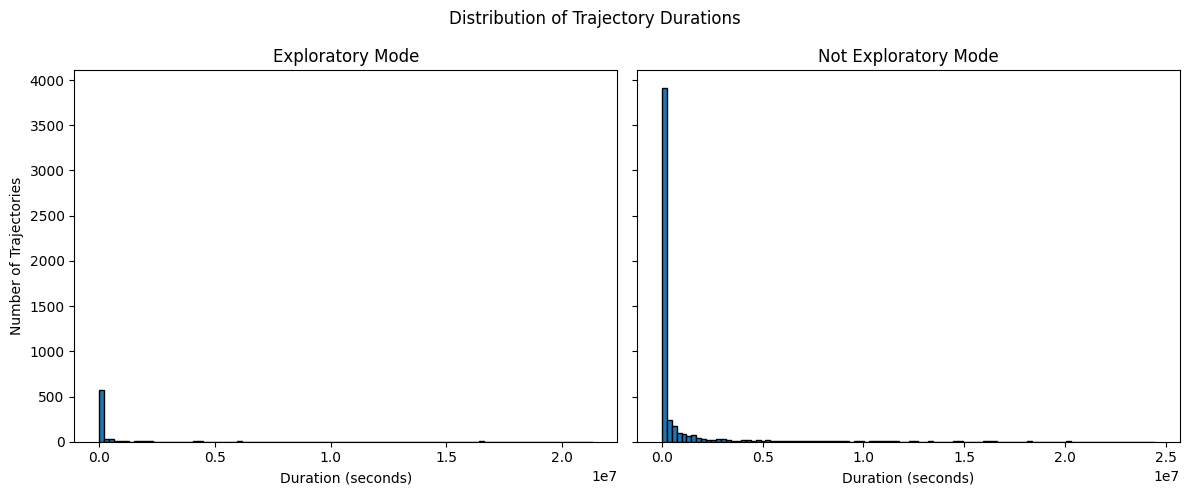

In [30]:
# Sort dataset by timestamp
durations_exploratory_mode = get_trajectory_durations(exploratory_mode_df)
durations_not_exploratory_mode = get_trajectory_durations(not_exploratory_mode_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(durations_exploratory_mode["duration_seconds"], bins=100, edgecolor='black')
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Number of Trajectories")
axes[0].set_title("Exploratory Mode")

# Not exploratory mode
axes[1].hist(durations_not_exploratory_mode["duration_seconds"], bins=100, edgecolor='black')
axes[1].set_xlabel("Duration (seconds)")
axes[1].set_title("Not Exploratory Mode")

plt.suptitle("Distribution of Trajectory Durations")
plt.tight_layout()
plt.show()

Median outcome length (exploratory mode) 119.0
Median outcome length (not exploratory mode) 93.0


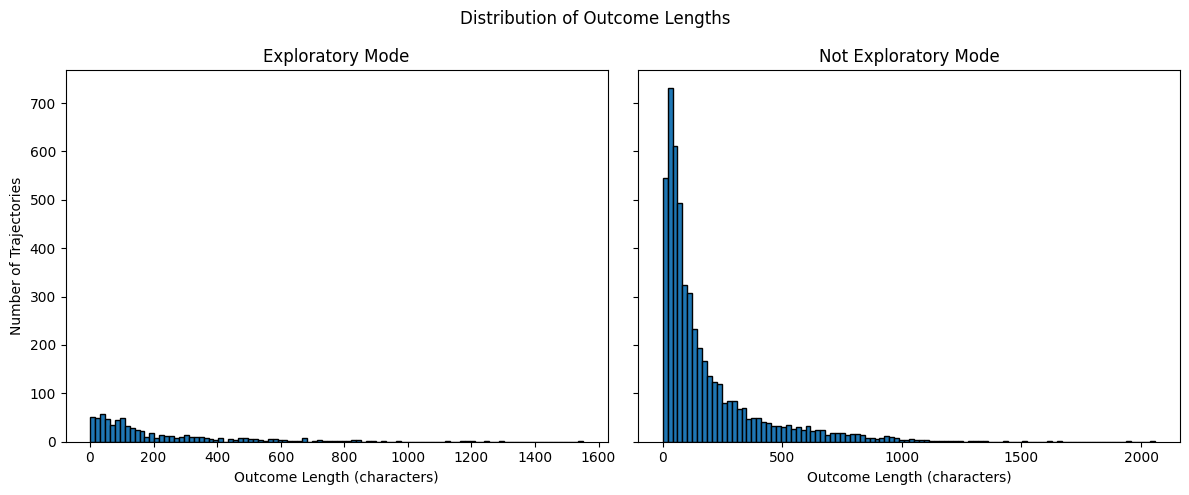

In [31]:
# Compute outcome lengths
print('Median outcome length (exploratory mode)', exploratory_mode_df["outcome_length"].median())
print('Median outcome length (not exploratory mode)', not_exploratory_mode_df["outcome_length"].median())

# Plot side-by-side histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(exploratory_mode_df["outcome_length"], bins=100, edgecolor='black')
axes[0].set_xlabel("Outcome Length (characters)")
axes[0].set_ylabel("Number of Trajectories")
axes[0].set_title("Exploratory Mode")

# Not exploratory mode
axes[1].hist(not_exploratory_mode_df["outcome_length"], bins=100, edgecolor='black')
axes[1].set_xlabel("Outcome Length (characters)")
axes[1].set_title("Not Exploratory Mode")

plt.suptitle("Distribution of Outcome Lengths")
plt.tight_layout()
plt.show()

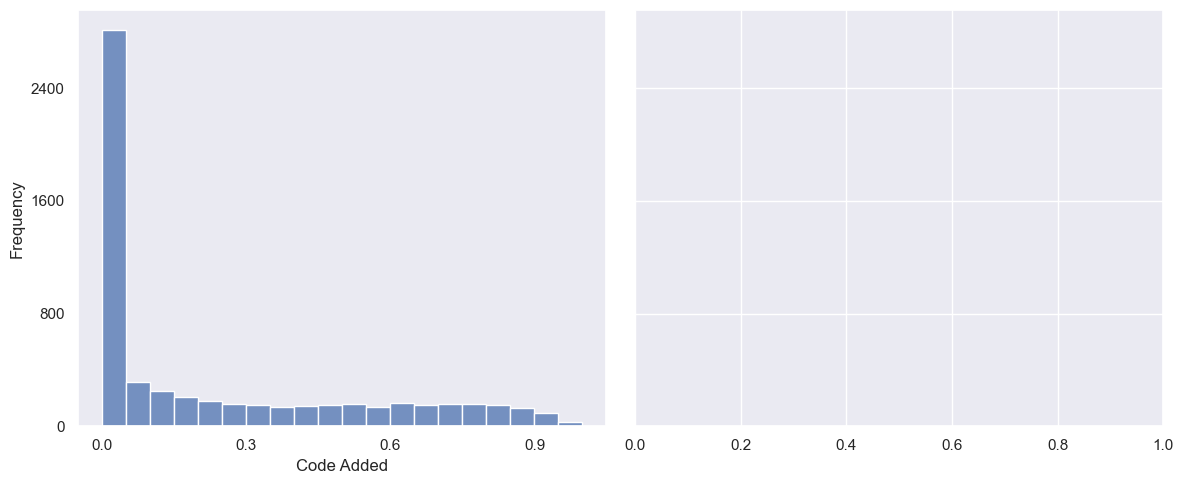

In [28]:
# --- 1) Canonical family extractor (stable names) ---
def get_family(model_name):
    n = str(model_name).lower()
    if   "gpt" in n:        return "GPT"
    if   "claude" in n:     return "Claude"
    if   "gemini" in n:     return "Gemini"
    if   "anonymous" in n:  return "Anonymous"
    if   "llama" in n:      return "Llama"
    if   "qwen" in n:       return "Qwen"
    if   "deepseek" in n:   return "Deepseek"
    if   "codestral" in n:  return "Codestral"
    return "Other"

# --- 2) Fixed palette per family (from your scheme) ---
family_palette = {
    "GPT":        (0.12156862745098039, 0.4666666666666667, 0.7058823529411765, 1.0),  # blue
    "Claude":     (1.0, 0.4980392156862745, 0.054901960784313725, 1.0),                 # orange
    "Llama":      (0.17254901960784313, 0.6274509803921569, 0.17254901960784313, 1.0),  # green
    "Gemini":     (0.8392156862745098, 0.15294117647058825, 0.1568627450980392, 1.0),   # red
    "Qwen":       (0.5803921568627451, 0.403921568627451, 0.7411764705882353, 1.0),     # purple
    "Deepseek":   (0.5490196078431373, 0.33725490196078434, 0.29411764705882354, 1.0),  # brown
    "Codestral":  (0.8901960784313725, 0.4666666666666667, 0.7607843137254902, 1.0),    # pink
    "Anonymous":  (0.4980392156862745, 0.4980392156862745, 0.4980392156862745, 1.0),    # gray
    "Other":      (0.2, 0.2, 0.2, 1.0),                                                 # dark gray fallback
}

# --- 3) Counts per model for each mode ---
exploratory_counts = exploratory_mode_df["model"].value_counts().sort_index()
not_exploratory_counts = not_exploratory_mode_df["model"].value_counts().sort_index()

# Colors per bar based on family mapping
exp_colors = [family_palette.get(get_family(m), family_palette["Other"]) for m in exploratory_counts.index]
nonexp_colors = [family_palette.get(get_family(m), family_palette["Other"]) for m in not_exploratory_counts.index]

# --- 4) Plot with separate y-axes ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
axes[0].set_xlabel("Code Added")
axes[0].set_ylabel("Frequency")
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
axes[0].yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
axes[0].grid(False)

# Exploratory
axes[0].bar(exploratory_counts.index, exploratory_counts.values, edgecolor='black', color=exp_colors)
axes[0].set_title("Exploratory Mode")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Count of Trajectories")
axes[0].tick_params(axis='x', rotation=45)

# Not exploratory
axes[1].bar(not_exploratory_counts.index, not_exploratory_counts.values, edgecolor='black', color=nonexp_colors)
axes[1].set_title("Not Exploratory Mode")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Count of Trajectories")
axes[1].tick_params(axis='x', rotation=45)

# Legend (only show families that appear)
families_present = sorted(set([get_family(m) for m in exploratory_counts.index] +
                              [get_family(m) for m in not_exploratory_counts.index]))
handles = [plt.Rectangle((0,0),1,1, color=family_palette[f]) for f in families_present]
fig.legend(handles, families_present, title="Model Family", loc="upper center", ncol=4)

plt.suptitle("Trajectory Counts per Model (Exploratory vs. Not Exploratory)")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

exploratory_counts = exploratory_mode_df["model"].value_counts()
not_exploratory_counts = not_exploratory_mode_df["model"].value_counts()

# Combine into a single DataFrame (aligns models automatically)
contingency = pd.DataFrame({
    "Exploratory": exploratory_counts,
    "Not Exploratory": not_exploratory_counts
}).fillna(0).astype(int)

print(contingency.head())

# Run chi-squared test
chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-squared statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)

residuals = (contingency - expected) / expected**0.5
residuals_df = pd.DataFrame(residuals, columns=contingency.columns)
print(residuals_df)
# print(len(last_rows[last_rows['percent_added'] <= 0.05]), len(last_rows))

Average percent_remaining: 0.5214871522291891
Median percent_remaining: 0.5730337078651685
Average percent_remaining: 0.5600573427088981
Median percent_remaining: 0.6355140186915887
Statistical significance 1699032.0 0.02909668940843606


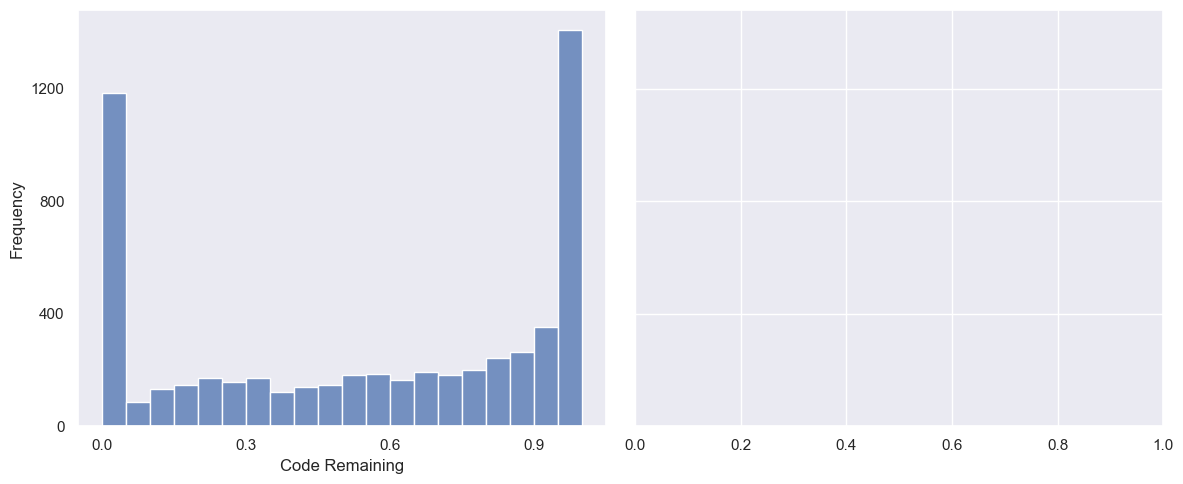

In [27]:
# Get last rows for both modes
last_rows_exploratory = get_trajectory_last_row(exploratory_mode_df)
last_rows_not_exploratory = get_trajectory_last_row(not_exploratory_mode_df)

stat, p = mannwhitneyu(last_rows_exploratory["percent_remaining"], last_rows_not_exploratory["percent_remaining"], alternative="two-sided")  # or "greater"/"less"
print('Statistical significance', stat, p)

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(last_rows_exploratory["percent_remaining"], bins=20, edgecolor="black")
axes[0].set_xlabel("Code Remaining")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Exploratory Mode (80% Remaining)")
axes[0].axvline(0.65, color="red", linestyle="--", linewidth=2)
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
axes[0].yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
axes[0].grid(False)

# Not exploratory mode
axes[1].hist(last_rows_not_exploratory["percent_remaining"], bins=20, edgecolor="black")
axes[1].set_xlabel("Code Remaining")
axes[1].set_title("Not Exploratory Mode (80% Remaining)")
axes[1].axvline(0.72, color="red", linestyle="--", linewidth=2)

plt.suptitle("Distribution of Final Code Remaining per Trajectory")
plt.tight_layout()
plt.show()

Average chars_added: 160.35294117647058
Median chars_added: 11.0
Average chars_added: 184.56786757546251
Median chars_added: 27.0
Statistical significance 1616005.5 2.5405067881051215e-05


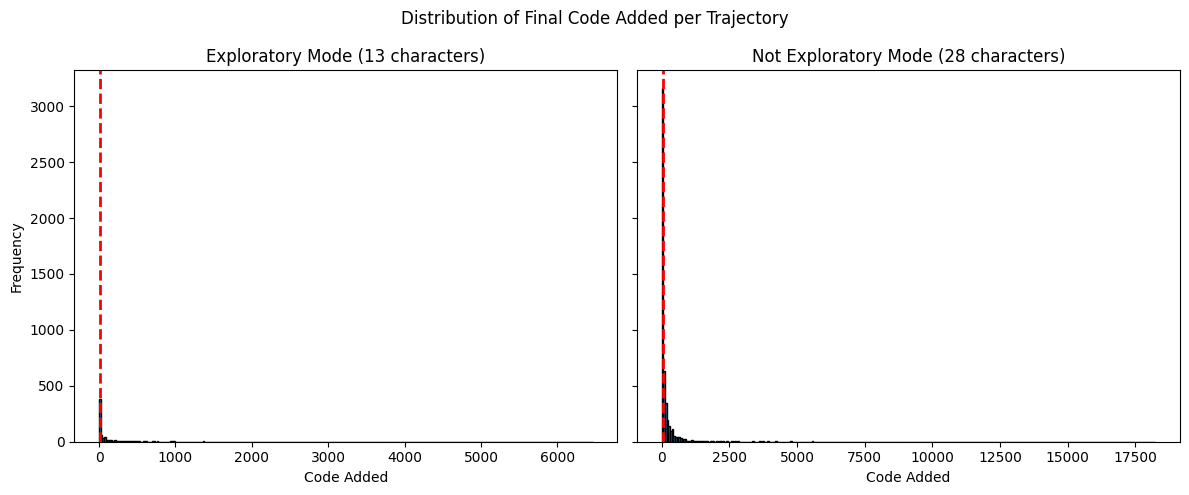

In [34]:
# Get the amount of code added at the end of each trajectory
last_rows_exploratory = get_trajectory_last_row(exploratory_mode_df, metric="chars_added")
last_rows_not_exploratory = get_trajectory_last_row(not_exploratory_mode_df, metric="chars_added")

stat, p = mannwhitneyu(last_rows_exploratory["chars_added"], last_rows_not_exploratory["chars_added"], alternative="two-sided")  # or "greater"/"less"
print('Statistical significance', stat, p)

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(last_rows_exploratory["chars_added"], bins=300, edgecolor="black")
axes[0].set_xlabel("Code Added")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Exploratory Mode (13 characters)")
axes[0].axvline(13, color="red", linestyle="--", linewidth=2)

# Not exploratory mode
axes[1].hist(last_rows_not_exploratory["chars_added"], bins=300, edgecolor="black")
axes[1].set_xlabel("Code Added")
axes[1].set_title("Not Exploratory Mode (28 characters)")
axes[1].axvline(28, color="red", linestyle="--", linewidth=2)

plt.suptitle("Distribution of Final Code Added per Trajectory")
plt.tight_layout()
plt.show()

Average percent_added: 0.2563032553996205
Median percent_added: 0.09350649350649351
Average percent_added: 0.32719658872272045
Median percent_added: 0.21428571428571427
Statistical significance 1564827.0 4.9530202573416343e-08


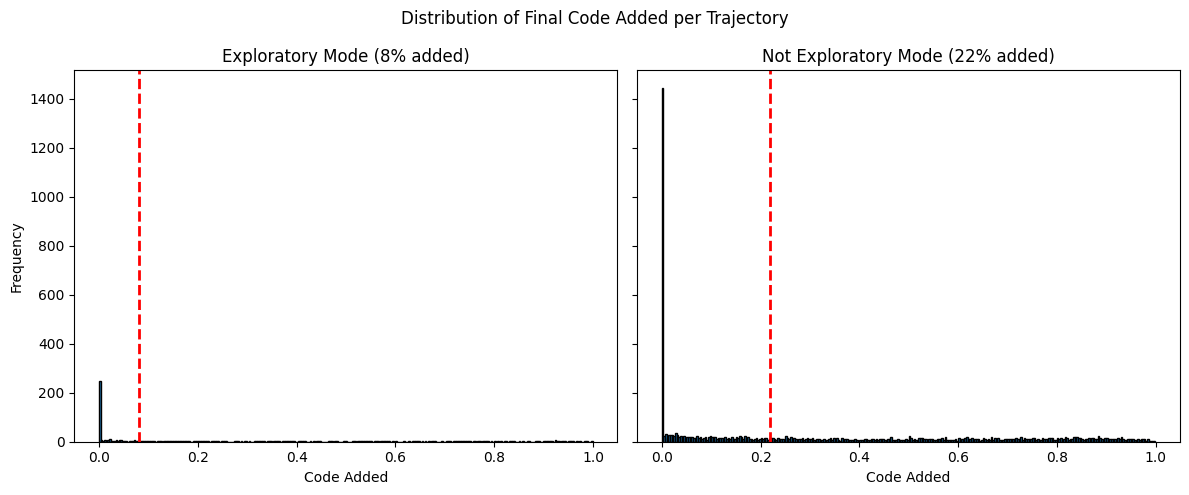

In [35]:
# Get the amount of code added at the end of each trajectory
last_rows_exploratory = get_trajectory_last_row(exploratory_mode_df, metric="percent_added")
last_rows_not_exploratory = get_trajectory_last_row(not_exploratory_mode_df, metric="percent_added")

stat, p = mannwhitneyu(last_rows_exploratory["percent_added"], last_rows_not_exploratory["percent_added"], alternative="two-sided")  # or "greater"/"less"
print('Statistical significance', stat, p)

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(last_rows_exploratory["percent_added"], bins=300, edgecolor="black")
axes[0].set_xlabel("Code Added")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Exploratory Mode (8% added)")
axes[0].axvline(0.08, color="red", linestyle="--", linewidth=2)

# Not exploratory mode
axes[1].hist(last_rows_not_exploratory["percent_added"], bins=300, edgecolor="black")
axes[1].set_xlabel("Code Added")
axes[1].set_title("Not Exploratory Mode (22% added)")
axes[1].axvline(0.22, color="red", linestyle="--", linewidth=2)

plt.suptitle("Distribution of Final Code Added per Trajectory")
plt.tight_layout()
plt.show()

In [21]:
print(dataset_df.columns)
print(len(dataset_df['outcome_pair_id'].unique()))
print(len(dataset_df['outcome_completion_id'].unique()))

Index(['outcome_pair_completion_id', 'outcome_pair_id',
       'outcome_completion_id', 'outcome', 'outcome_snippet',
       'outcome_full_snippet', 'outcome_timestamp', 'outcome_full_file',
       'outcome_snippet_start_line', 'outcome_snippet_end_line',
       'edit_completion_id', 'edit_snippet', 'edit_full_file',
       'edit_timestamp', 'edit_full_snippet', 'all_changed_lines',
       'is_outcome', 'user_id', 'model', 'codebert_score',
       'outcome_context_and_removed_lines', 'edit_snippet_with_extra_context',
       'fileType', 'time_since_completion', 'edit_timestamp_readable',
       'percent_remaining', 'percent_added', 'chars_added', 'outcome_length',
       'outcome_line_count'],
      dtype='object')
5832
5831


In [23]:
from tqdm import tqdm

part1_part2_system_prompt = """You are a helpful assistant that describes code files in a single,
concise sentence. Focus on the main purpose and functionality of the
code. Keep descriptions clear, technical, and under 100 characters. Do
not mention file names or extensions in your description.
General Prompt
Describe this code in one sentence
"""

part1_prompt = """
Describe this code in one sentence
"""

client = OpenAI()

# Parameters
MAX_RETRIES = 5
BASE_DELAY = 2  # seconds
SAVE_EVERY = 5  # save progress every N rows
SAVE_PATH = "results_progress.csv"

# Get all the outcomes we want to process
grouped_df = (
    dataset_df[["outcome_pair_id", "outcome", "outcome_full_file"]]
    .copy()
    .groupby("outcome_pair_id", as_index=False)
    .first()   # or .agg({'outcome': 'first', 'outcome_full_file': 'first'})
)

# Initialize results DataFrame
if os.path.exists(SAVE_PATH):
    print(f"Resuming from existing file: {SAVE_PATH}")
    results_df = pd.read_csv(SAVE_PATH)
    processed_ids = set(results_df["outcome_pair_id"])
else:
    results_df = pd.DataFrame(columns=["index", "outcome_pair_id", "response"])
    processed_ids = set()

# Loop through dataset
for i, row in tqdm(grouped_df.iterrows(), total=len(grouped_df)):
    outcome_file = row["outcome_full_file"]
    outcome_pair_id = row["outcome_pair_id"]

    # Skip rows we've already processed
    if outcome_pair_id in processed_ids:
        continue

    # Try the API call with retries
    for attempt in range(MAX_RETRIES):
        try:
            response = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": part1_part2_system_prompt},
                    {"role": "user", "content": part1_prompt + "\n" + outcome_file}
                ],
            )
            result_text = response.choices[0].message.content.strip()
            break  # success

        except (RateLimitError, APIError) as e:
            sleep_time = BASE_DELAY * (2 ** attempt) + random.uniform(0, 1)
            print(f"Rate limit/API error on row {i}: {e}. Retrying in {sleep_time:.1f}s...")
            time.sleep(sleep_time)
        except Exception as e:
            print(f"Unexpected error on row {i}: {e}")
            result_text = f"ERROR: {e}"
            break
    else:
        result_text = "ERROR: Max retries exceeded"

    # Append new result
    results_df.loc[len(results_df)] = {
        "index": i,
        "outcome_pair_id": outcome_pair_id,
        "response": result_text
    }
    processed_ids.add(outcome_pair_id)

    # Save progress periodically
    if (len(results_df) % SAVE_EVERY) == 0:
        results_df.to_csv(SAVE_PATH, index=False)
        print(f"Progress saved ({len(results_df)} rows)")

# Final save
results_df.to_csv(SAVE_PATH, index=False)
print(f"✅ Done! Saved all results to {SAVE_PATH}")

Resuming from existing file: results_progress.csv


 11%|█████████▎                                                                            | 628/5832 [00:00<00:07, 694.51it/s]

Progress saved (5360 rows)


 12%|██████████▍                                                                            | 698/5832 [00:08<01:21, 63.30it/s]

Progress saved (5365 rows)


...

Progress saved (5825 rows)


100%|█████████████████████████████████████████████████████████████████████████████████████▋| 5814/5832 [07:14<00:01, 17.37it/s]

Progress saved (5830 rows)


100%|██████████████████████████████████████████████████████████████████████████████████████| 5832/5832 [07:16<00:00, 13.38it/s]

✅ Done! Saved all results to results_progress.csv


In [25]:
part2_prompt = """You are a code organization expert.
Analyze the provided code descriptions and:
1. Identify 5-10 main functional clusters or themes
2. Assign each description to the most appropriate cluster
3. Provide a brief name and description for each cluster
4. Format the response as valid JSON with the following structure:
{
    "clusters": [
        {
            "name": "cluster_name",
            "description": "brief cluster description",
            "descriptions": ["description", "description2"]
        }
    ]
}
"""

client = OpenAI()

# Parameters
MAX_RETRIES = 5
BASE_DELAY = 2  # seconds
SAVE_PATH = "results_progress.csv"

# --- Step 1: Read CSV and combine responses ---
df = pd.read_csv(SAVE_PATH)
df = df[df["response"].notna()]
responses = df["response"].astype(str).tolist()

# Split into two batches
midpoint = len(responses) // 2
batches = [responses[:midpoint], responses[midpoint:]]

print(f"Loaded {len(df)} responses, split into {len(batches)} batches of ~{midpoint} each.")

results = []

# --- Step 2: Process each batch ---
for i, batch in enumerate(batches, 1):
    lines = "\n".join(batch)
    print(f"\n--- Processing batch {i}/{len(batches)} ({len(batch)} responses) ---")

    for attempt in range(MAX_RETRIES):
        try:
            response = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": part1_part2_system_prompt},
                    {"role": "user", "content": part2_prompt + "\n" + lines}
                ],
            )
            result_text = response.choices[0].message.content.strip()
            results.append(result_text)
            print(f"✅ Batch {i} done!")
            break  # success

        except (RateLimitError, APIError) as e:
            sleep_time = BASE_DELAY * (2 ** attempt) + random.uniform(0, 1)
            print(f"Rate limit/API error on attempt {attempt + 1}: {e}. Retrying in {sleep_time:.1f}s...")
            time.sleep(sleep_time)
        except Exception as e:
            print(f"Unexpected error: {e}")
            results.append(f"ERROR in batch {i}: {e}")
            break
    else:
        results.append(f"ERROR: Max retries exceeded for batch {i}")

# --- Step 3: Combine results ---
combined_result = "\n\n".join(results)
print("\n✅ All batches completed!")
print(combined_result)

Loaded 5832 responses, split into 2 batches of ~2916 each.

--- Processing batch 1/2 (2916 responses) ---
✅ Batch 1 done!

--- Processing batch 2/2 (2916 responses) ---
✅ Batch 2 done!

✅ All batches completed!
```json
{
    "clusters": [
        {
            "name": "Data Processing and Analysis",
            "description": "Transforming and analyzing data across various domains.",
            "descriptions": [
                "Processes financial data from daily and hourly timeframes, combining and analyzing price, moving average, and RSI statistics.",
                "Loads and preprocesses time series data from Excel files for daily and hourly price analysis.",
                "Requests historical stock data for analysis and visualizes results.",
                "Processes loading data from multiple CSV files for analysis, cleaning, and merging."
            ]
        },
        {
            "name": "Machine Learning and AI",
            "description": "Building and training mode

In [27]:
part3_system_prompt = """
Please categorize the following code into one of these categories:
- Data Processing, Analysis, and Visualization: Transforming, analyzing, or visualizing data across various domains.
- Machine Learning and AI: Building and training models for various applications.
- Web Application Development: Creating interactive web applications and APIs.
- Document and Media Processing: Processing documents and media files for extraction and conversion.
- Game Development: Creating interactive games and simulations.
- API Integration and Web Scraping: Integrating with external APIs and scraping web data.
- Data Storage and Management: Functions and methods to manage, process, or operate on application data.
- User Interfaces and Tools: Components and frameworks for building interactive user interfaces or user-facing tools.
- Testing and Validation: Frameworks and implementations for unit and integration testing.
"""

part3_prompt = """Only respond with the exact category name that best fits. No other text.
Here’s the code:
"""

client = OpenAI()

# Parameters
MAX_RETRIES = 5
BASE_DELAY = 2  # seconds
SAVE_EVERY = 5  # save progress every N rows
SAVE_PATH = "results_progress2.csv"

# Get all the outcomes we want to process
grouped_df = (
    dataset_df[["outcome_pair_id", "outcome", "outcome_full_file"]]
    .copy()
    .groupby("outcome_pair_id", as_index=False)
    .first()   # or .agg({'outcome': 'first', 'outcome_full_file': 'first'})
)

# Initialize results DataFrame
if os.path.exists(SAVE_PATH):
    print(f"Resuming from existing file: {SAVE_PATH}")
    results_df = pd.read_csv(SAVE_PATH)
    processed_ids = set(results_df["outcome_pair_id"])
else:
    results_df = pd.DataFrame(columns=["index", "outcome_pair_id", "response"])
    processed_ids = set()

# Loop through dataset
for i, row in tqdm(grouped_df.iterrows(), total=len(grouped_df)):
    outcome_file = row["outcome_full_file"]
    outcome_pair_id = row["outcome_pair_id"]

    # Skip rows we've already processed
    if outcome_pair_id in processed_ids:
        continue

    # Try the API call with retries
    for attempt in range(MAX_RETRIES):
        try:
            response = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": part3_system_prompt},
                    {"role": "user", "content": part3_prompt + "\n" + outcome_file}
                ],
            )
            result_text = response.choices[0].message.content.strip()
            break  # success

        except (RateLimitError, APIError) as e:
            sleep_time = BASE_DELAY * (2 ** attempt) + random.uniform(0, 1)
            print(f"Rate limit/API error on row {i}: {e}. Retrying in {sleep_time:.1f}s...")
            time.sleep(sleep_time)
        except Exception as e:
            print(f"Unexpected error on row {i}: {e}")
            result_text = f"ERROR: {e}"
            break
    else:
        result_text = "ERROR: Max retries exceeded"

    # Append new result
    results_df.loc[len(results_df)] = {
        "index": i,
        "outcome_pair_id": outcome_pair_id,
        "response": result_text
    }
    processed_ids.add(outcome_pair_id)

    # Save progress periodically
    if (len(results_df) % SAVE_EVERY) == 0:
        results_df.to_csv(SAVE_PATH, index=False)
        print(f"Progress saved ({len(results_df)} rows)")

# Final save
results_df.to_csv(SAVE_PATH, index=False)
print(f"✅ Done! Saved all results to {SAVE_PATH}")

  0%|                                                                | 5/5832 [00:06<1:45:29,  1.09s/it]

Progress saved (5 rows)


  0%|                                                               | 10/5832 [00:11<1:48:00,  1.11s/it]

Progress saved (10 rows)


  0%|▏                                                              | 15/5832 [00:14<1:14:12,  1.31it/s]

...

Progress saved (5825 rows)


100%|████████████████████████████████████████████████████████████▉| 5830/5832 [9:23:04<00:01,  1.20it/s]

Progress saved (5830 rows)


100%|█████████████████████████████████████████████████████████████| 5832/5832 [9:23:05<00:00,  5.79s/it]

✅ Done! Saved all results to results_progress2.csv


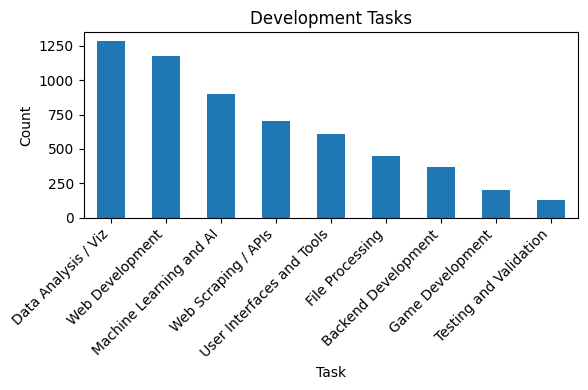

In [38]:
SAVE_PATH = "results_progress2.csv"
df = pd.read_csv(SAVE_PATH)
# Map old labels to new ones
label_map = {
    "API Integration and Web Scraping": "Web Scraping / APIs",
    "Web Application Development": "Web Development",
    "Data Processing, Analysis, and Visualization": "Data Analysis / Viz",
    "Document and Media Processing": "File Processing",
    "Data Storage and Management": "Backend Development"
}

# Apply the mapping
df["response_mapped"] = df["response"].replace(label_map)

# Get frequencies sorted by count
response_counts = df["response_mapped"].value_counts().sort_values(ascending=False)

# Plot the histogram
plt.figure(figsize=(6,4))
response_counts.plot(kind="bar")
plt.title("Development Tasks")
plt.ylabel("Count")
plt.xlabel("Task")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Analysis by Model

Next, we look at some basic metrics for visualizing differences in model performance### Type of completion (single-line vs. multi-line)

Average percent_remaining: 0.5554477023172044
Median percent_remaining: 0.6287683031869078


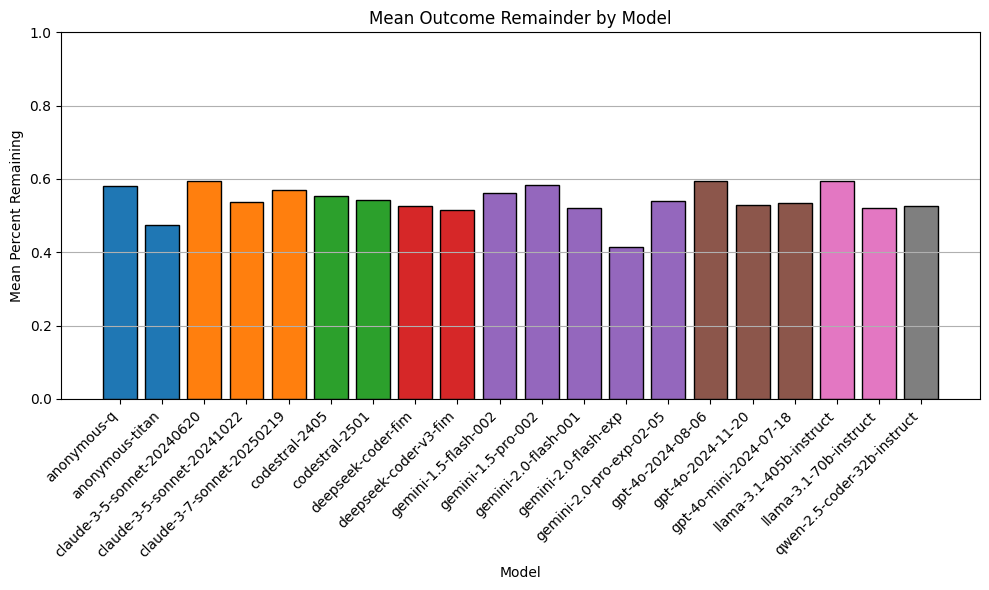

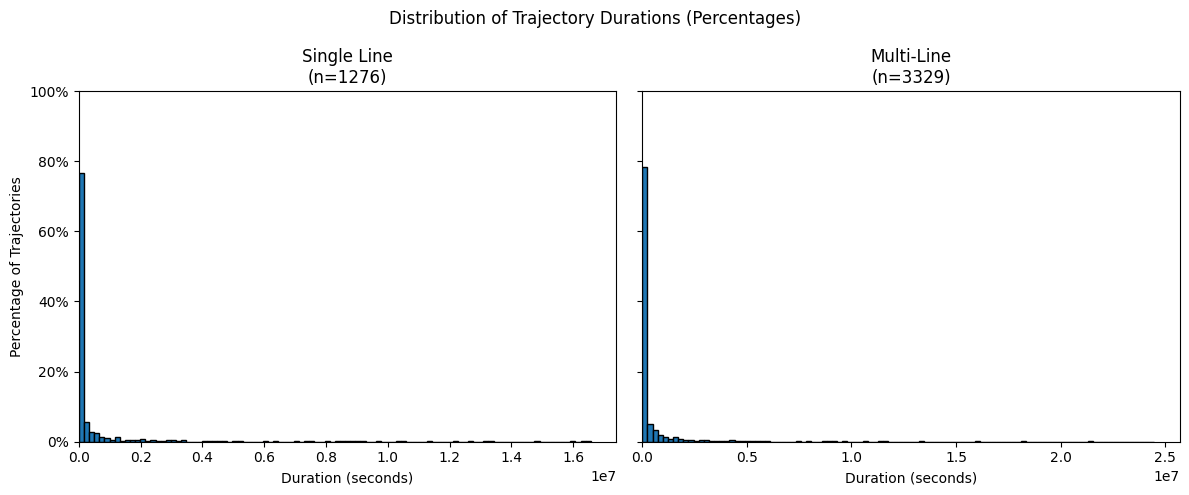

In [37]:
# Sort dataset by timestamp
durations_single_line = get_trajectory_durations(single_line_df)
durations_multi_line = get_trajectory_durations(multi_line_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Helper to plot percentages
def plot_percentage_hist(ax, data, title):
    data = data.dropna()
    weights = np.ones(len(data)) / len(data)  # normalize to proportion
    ax.hist(data, bins=100, edgecolor='black', weights=weights)
    ax.set_xlabel("Duration (seconds)")
    ax.set_title(f"{title}\n(n={len(data)})")
    ax.set_xlim(left=0)
    ax.set_ylim(0, 1.0)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y*100:.0f}%"))

plot_percentage_hist(axes[0], durations_single_line["duration_seconds"], "Single Line")
axes[0].set_ylabel("Percentage of Trajectories")

plot_percentage_hist(axes[1], durations_multi_line["duration_seconds"], "Multi-Line")

plt.suptitle("Distribution of Trajectory Durations (Percentages)")
plt.tight_layout()
plt.show

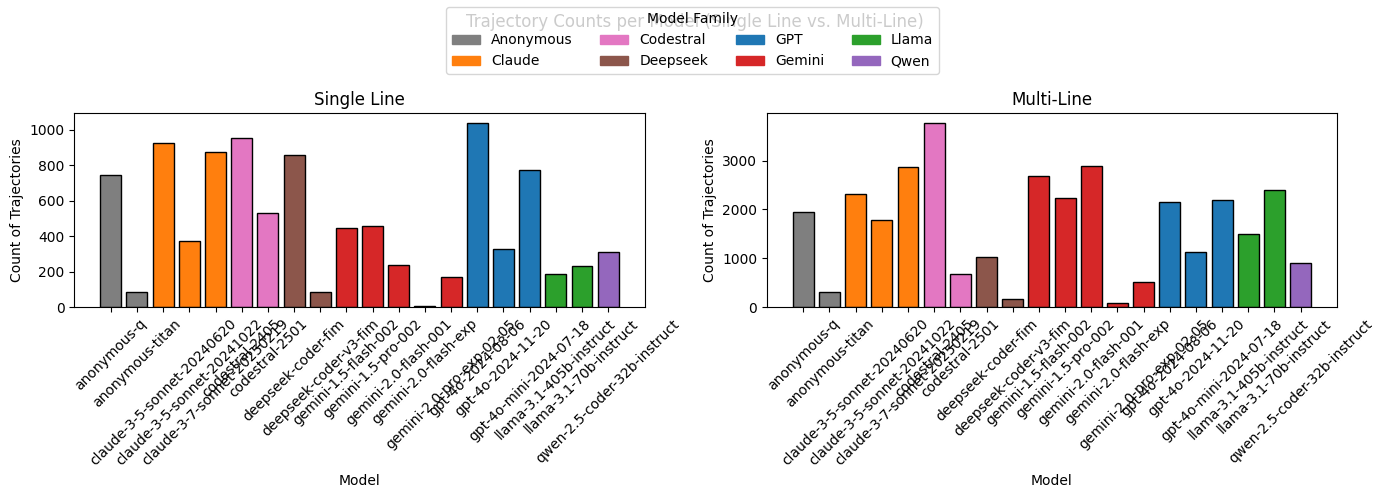

Chi-squared statistic: 2297.0359164603246
Degrees of freedom: 19
p-value: 0.0
                             Single Line  Multi-Line
model                                               
anonymous-q                     5.882946   -3.150281
anonymous-titan                -0.489420    0.262081
claude-3-5-sonnet-20240620      7.571044   -4.054246
claude-3-5-sonnet-20241022     -4.838620    2.591050
claude-3-7-sonnet-20250219      1.322210   -0.708035
codestral-2405                 -3.121826    1.671718
codestral-2501                 15.955624   -8.544137
deepseek-coder-fim             21.284968  -11.397967
deepseek-coder-v3-fim           4.327764   -2.317490
gemini-1.5-flash-002           -9.551152    5.114582
gemini-1.5-pro-002             -5.769924    3.089758
gemini-2.0-flash-001          -17.450580    9.344676
gemini-2.0-flash-exp           -3.339058    1.788044
gemini-2.0-pro-exp-02-05        1.480533   -0.792816
gpt-4o-2024-08-06              12.360333   -6.618881
gpt-4o-2024-11-20    

In [45]:
# --- 1) Canonical family extractor (stable names) ---
def get_family(model_name):
    n = str(model_name).lower()
    if   "gpt" in n:        return "GPT"
    if   "claude" in n:     return "Claude"
    if   "gemini" in n:     return "Gemini"
    if   "anonymous" in n:  return "Anonymous"
    if   "llama" in n:      return "Llama"
    if   "qwen" in n:       return "Qwen"
    if   "deepseek" in n:   return "Deepseek"
    if   "codestral" in n:  return "Codestral"
    return "Other"

# --- 2) Fixed palette per family (from your scheme) ---
family_palette = {
    "GPT":        (0.12156862745098039, 0.4666666666666667, 0.7058823529411765, 1.0),  # blue
    "Claude":     (1.0, 0.4980392156862745, 0.054901960784313725, 1.0),                 # orange
    "Llama":      (0.17254901960784313, 0.6274509803921569, 0.17254901960784313, 1.0),  # green
    "Gemini":     (0.8392156862745098, 0.15294117647058825, 0.1568627450980392, 1.0),   # red
    "Qwen":       (0.5803921568627451, 0.403921568627451, 0.7411764705882353, 1.0),     # purple
    "Deepseek":   (0.5490196078431373, 0.33725490196078434, 0.29411764705882354, 1.0),  # brown
    "Codestral":  (0.8901960784313725, 0.4666666666666667, 0.7607843137254902, 1.0),    # pink
    "Anonymous":  (0.4980392156862745, 0.4980392156862745, 0.4980392156862745, 1.0),    # gray
    "Other":      (0.2, 0.2, 0.2, 1.0),                                                 # dark gray fallback
}

# --- 3) Counts per model for each mode ---
single_line_counts = single_line_df["model"].value_counts().sort_index()
multi_line_counts = multi_line_df["model"].value_counts().sort_index()

# Colors per bar based on family mapping
single_line_colors = [family_palette.get(get_family(m), family_palette["Other"]) for m in single_line_counts.index]
multi_line_colors = [family_palette.get(get_family(m), family_palette["Other"]) for m in multi_line_counts.index]

# --- 4) Plot with separate y-axes ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# Exploratory
axes[0].bar(single_line_counts.index, single_line_counts.values, edgecolor='black', color=single_line_colors)
axes[0].set_title("Single Line")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Count of Trajectories")
axes[0].tick_params(axis='x', rotation=45)

# Not exploratory
axes[1].bar(multi_line_counts.index, multi_line_counts.values, edgecolor='black', color=multi_line_colors)
axes[1].set_title("Multi-Line")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Count of Trajectories")
axes[1].tick_params(axis='x', rotation=45)

# Legend (only show families that appear)
families_present = sorted(set([get_family(m) for m in single_line_counts.index] +
                              [get_family(m) for m in multi_line_counts.index]))
handles = [plt.Rectangle((0,0),1,1, color=family_palette[f]) for f in families_present]
fig.legend(handles, families_present, title="Model Family", loc="upper center", ncol=4)

plt.suptitle("Trajectory Counts per Model (Single Line vs. Multi-Line)")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

single_line_counts = single_line_df["model"].value_counts()
multi_line_counts = multi_line_df["model"].value_counts()

# Combine into a single DataFrame (aligns models automatically)
contingency = pd.DataFrame({
    "Single Line": single_line_counts,
    "Multi-Line": multi_line_counts
}).fillna(0).astype(int)

# Run chi-squared test
chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-squared statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)

residuals = (contingency - expected) / expected**0.5
residuals_df = pd.DataFrame(residuals, columns=contingency.columns)
print(residuals_df)

In [45]:
# Check whether the differences between each of the models are statistically different
from itertools import combinations

def statistic(x, y, axis):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)

# ------------------------------------------------------------
# Configure this if your metric column isn't named 'score'
VALUE_COL = "percent_added"   # e.g., "accuracy", "metric", etc.
MODEL_COL = "model"   # change if your model id column is different
# Optionally set n_resamples=None to use SciPy's default
N_RESAMPLES = None     # e.g., 5000, 20000, or None for default
RANDOM_STATE = 42      # set to an int for reproducibility or None
# ------------------------------------------------------------

# last_rows = get_trajectory_last_row(dataset_df)
# # pval = stats.permutation_test((system_two, system_one), statistic=statistic, vectorized=True, n_resamples=5000).pvalue

# # Ensure numeric values (drop NaNs)
# last_rows = last_rows.copy()
# last_rows = last_rows[pd.to_numeric(last_rows[VALUE_COL], errors='coerce').notna()]

# # Build arrays per model
# model_to_values = {
#     m: last_rows.loc[last_rows[MODEL_COL] == m, VALUE_COL].to_numpy()
#     for m in last_rows[MODEL_COL].unique()
# }

# # Two-sample mean difference (A - B)
# def mean_diff(x, y):
#     return np.mean(x) - np.mean(y)

# results = []
# for a, b in combinations(model_to_values.keys(), 2):
#     xa = model_to_values[a]
#     xb = model_to_values[b]
#     # Skip degenerate cases
#     if xa.size == 0 or xb.size == 0:
#         continue

#     test = stats.permutation_test(
#         data=(xa, xb),
#         statistic=mean_diff,       # and signature (x, y) -> float
#         vectorized=False,          # simpler; sizes may differ
#         alternative="two-sided",
#         permutation_type="independent",
#         random_state=RANDOM_STATE
#     )

#     results.append({
#         "model_a": a,
#         "model_b": b,
#         "n_a": xa.size,
#         "n_b": xb.size,
#         "mean_diff_a_minus_b": float(np.mean(xa) - np.mean(xb)),
#         "pvalue": float(test.pvalue),
#         "statistic": float(test.statistic) if hasattr(test, "statistic") else float(np.mean(xa) - np.mean(xb))
#     })

pairwise_df = pd.DataFrame(results).sort_values("pvalue", ascending=True).reset_index(drop=True)
rej, p_bonf, alpha_bonf, _ = multipletests(pairwise_df["pvalue"].to_numpy(), alpha=0.05, method="bonferroni")
pairwise_df = pairwise_df.assign(
    p_bonf=p_bonf,
    alpha_bonf=alpha_bonf,
    reject_bonf=rej
).sort_values("p_bonf").reset_index(drop=True)

# Prints out true if there is any statistical difference, and false if there is none for all pairwise comaprisons
print(pairwise_df['reject_bonf'].any())
print(pairwise_df[pairwise_df['reject_bonf'] == True])

True
                      model_a                     model_b  n_a  n_b  \
0      gpt-4o-mini-2024-07-18      llama-3.1-70b-instruct  346  320   
1           gpt-4o-2024-08-06      llama-3.1-70b-instruct  453  320   
2  claude-3-5-sonnet-20240620           gpt-4o-2024-08-06  370  453   
3          deepseek-coder-fim      llama-3.1-70b-instruct  263  320   
4      llama-3.1-70b-instruct          gemini-1.5-pro-002  320  358   
5      llama-3.1-70b-instruct  claude-3-7-sonnet-20250219  320  437   
6      llama-3.1-70b-instruct                 anonymous-q  320  388   
7      llama-3.1-70b-instruct              codestral-2501  320  170   

   mean_diff_a_minus_b  pvalue  statistic  p_bonf  alpha_bonf  reject_bonf  
0             0.109909  0.0002   0.109909   0.038     0.00027         True  
1             0.138377  0.0002   0.138377   0.038     0.00027         True  
2            -0.098754  0.0002  -0.098754   0.038     0.00027         True  
3             0.136817  0.0002   0.136817   0.0

Average percent_remaining: 0.7480013424453749
Median percent_remaining: 0.875
Average percent_remaining: 0.6884953125162514
Median percent_remaining: 0.7775175644028103
Statistical significance 1769495.0 1.1454804903806134e-18


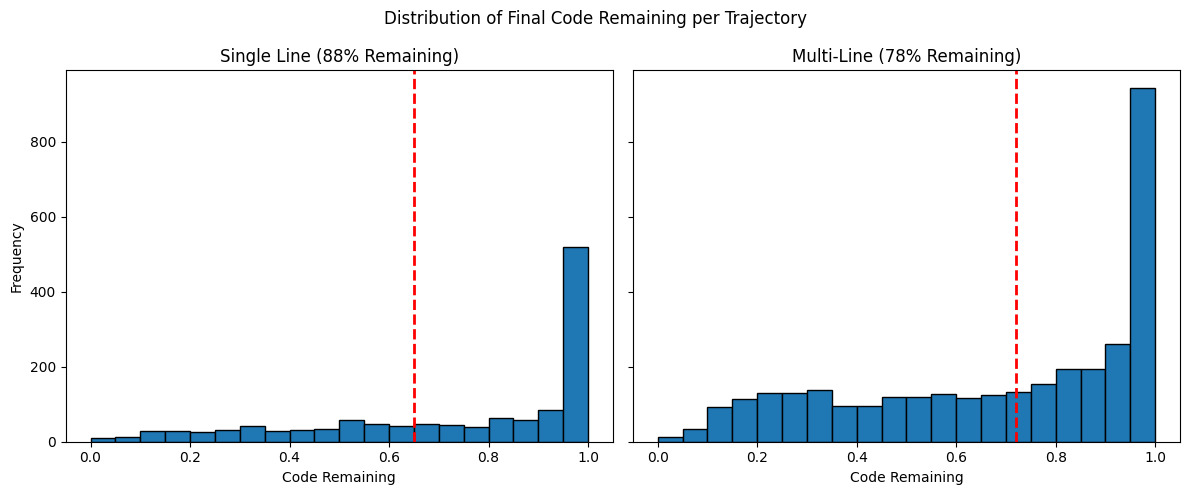

In [56]:
# Get last rows for both modes
last_rows_single_line = get_trajectory_last_row(single_line_df)
last_rows_multi_line = get_trajectory_last_row(multi_line_df)

stat, p = mannwhitneyu(last_rows_multi_line["percent_remaining"], last_rows_single_line["percent_remaining"], alternative="two-sided")  # or "greater"/"less"
print('Statistical significance', stat, p)

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(last_rows_single_line["percent_remaining"], bins=20, edgecolor="black")
axes[0].set_xlabel("Code Remaining")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Single Line (88% Remaining)")
axes[0].axvline(0.65, color="red", linestyle="--", linewidth=2)

# Not exploratory mode
axes[1].hist(last_rows_multi_line["percent_remaining"], bins=20, edgecolor="black")
axes[1].set_xlabel("Code Remaining")
axes[1].set_title("Multi-Line (78% Remaining)")
axes[1].axvline(0.72, color="red", linestyle="--", linewidth=2)

plt.suptitle("Distribution of Final Code Remaining per Trajectory")
plt.tight_layout()
plt.show()

In [57]:
last_rows = get_trajectory_last_row(dataset_df)

def classify_model(name):
    name = name.lower()
    
    # Determine if open or closed source
    if any(x in name for x in ["anonymous", "claude", "gemini", "gpt"]):
        open_source = False
    elif any(x in name for x in ["codestral", "deepseek", "llama", "qwen"]):
        open_source = True
    else:
        open_source = None  # unknown / fallback
    
    # Determine if smaller variant
    smaller_model = any(x in name for x in ["flash", "mini", "70b"])
    
    # Determine family (optional, helps grouping later)
    family = None
    for fam in ["anonymous", "claude", "gemini", "gpt", "codestral", "deepseek", "llama", "qwen"]:
        if fam in name:
            family = fam.capitalize()
            break
    
    return pd.Series({
        "open_source": open_source,
        "smaller_model": smaller_model,
        "family": family
    })

# Apply classifier
meta = last_rows["model"].apply(classify_model)
last_rows = pd.concat([last_rows, meta], axis=1)

# Ensure correct dtypes
last_rows["open_source"] = last_rows["open_source"].astype(float)   # 1=open, 0=closed
last_rows["smaller_model"] = last_rows["smaller_model"].astype(float)
last_rows["family"] = last_rows["family"].astype("category")

# Drop rows with missing family/open_source annotations if needed
last_rows = last_rows.dropna(subset=["open_source", "family"])

model = smf.mixedlm(
    "percent_remaining ~ open_source + smaller_model",
    data=last_rows,
    groups=last_rows["model"]
).fit()
print(model.summary())

Average percent_remaining: 0.5575657217758493
Median percent_remaining: 0.6347826086956522
             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: percent_remaining
No. Observations: 5291    Method:             REML             
No. Groups:       20      Scale:              0.1477           
Min. group size:  10      Log-Likelihood:     -2459.4783       
Max. group size:  544     Converged:          Yes              
Mean group size:  264.6                                        
----------------------------------------------------------------
                 Coef.   Std.Err.    z     P>|z|  [0.025  0.975]
----------------------------------------------------------------
Intercept         0.570     0.010  58.970  0.000   0.551   0.589
open_source      -0.020     0.014  -1.467  0.142  -0.047   0.007
smaller_model    -0.019     0.013  -1.437  0.151  -0.046   0.007
Group Var         0.000     0.001                               



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [42]:
model_stats = []

stat, p = mannwhitneyu(last_rows_single_line["chars_added"], last_rows_multi_line["chars_added"], alternative="two-sided")  # or "greater"/"less"
print('Statistical significance', stat, p)

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(last_rows_single_line["chars_added"], bins=300, edgecolor="black")
axes[0].set_xlabel("Code Added")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Single-Line (13 characters)")
axes[0].axvline(13, color="red", linestyle="--", linewidth=2)

# Not exploratory mode
axes[1].hist(last_rows_multi_line["chars_added"], bins=300, edgecolor="black")
axes[1].set_xlabel("Code Added")
axes[1].set_title("Multi-Line (28 characters)")
axes[1].axvline(28, color="red", linestyle="--", linewidth=2)

plt.suptitle("Distribution of Final Code Added per Trajectory")
plt.tight_layout()
plt.show()

Average percent_added: 0.60965950140662
Median percent_added: 0.696835954796604
Average percent_added: 0.34207369817637245
Median percent_added: 0.2676056338028169
Statistical significance 3123176.5 2.6228768856113976e-135


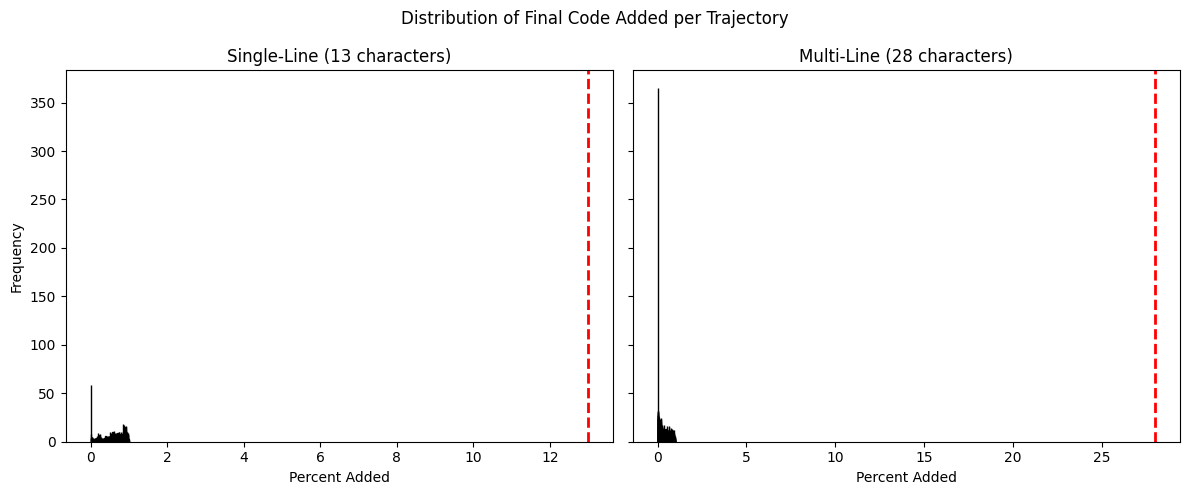

In [58]:
# Get the amount of code added at the end of each trajectory
last_rows_single_line = get_trajectory_last_row(single_line_df, metric="percent_added")
last_rows_multi_line = get_trajectory_last_row(multi_line_df, metric="percent_added")

stat, p = mannwhitneyu(last_rows_single_line["percent_added"], last_rows_multi_line["percent_added"], alternative="two-sided")  # or "greater"/"less"
print('Statistical significance', stat, p)

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Exploratory mode
axes[0].hist(last_rows_single_line["percent_added"], bins=300, edgecolor="black")
axes[0].set_xlabel("Percent Added")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Single-Line (13 characters)")
axes[0].axvline(13, color="red", linestyle="--", linewidth=2)

# Not exploratory mode
axes[1].hist(last_rows_multi_line["percent_added"], bins=300, edgecolor="black")
axes[1].set_xlabel("Percent Added")
axes[1].set_title("Multi-Line (28 characters)")
axes[1].axvline(28, color="red", linestyle="--", linewidth=2)

plt.suptitle("Distribution of Final Code Added per Trajectory")
plt.tight_layout()
plt.show()

## Analysis by Model

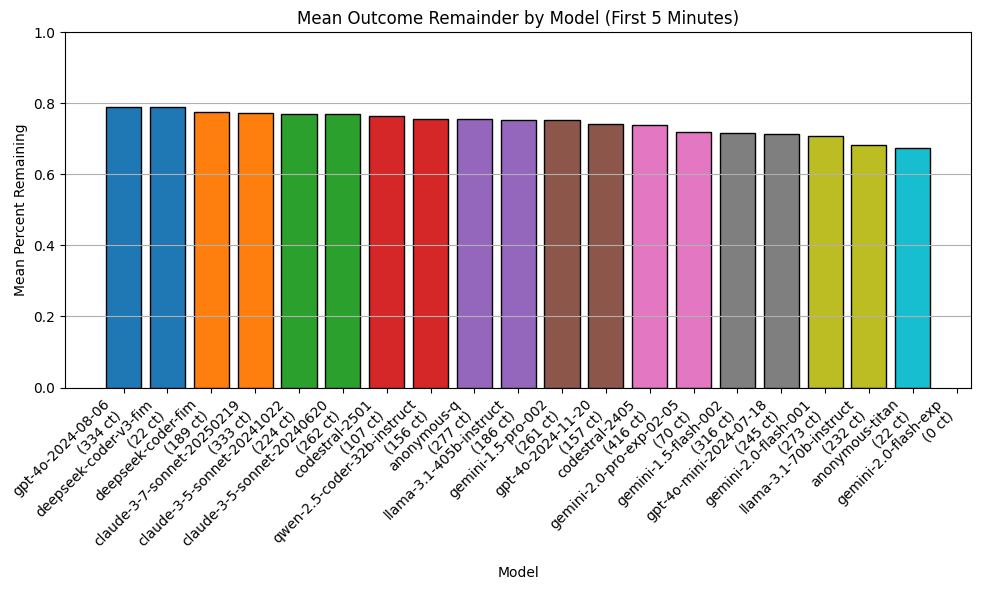

In [46]:
model_stats = []

for model in dataset_df["model"].unique():
    model_df = dataset_df[dataset_df["model"] == model]

    def mean_remainder_within(minutes):
        cutoff = minutes * 60  # convert to seconds
        subset = model_df[model_df["time_since_completion"] <= cutoff]
        return subset["percent_remaining"].mean() if not subset.empty else 0

    mean_length = model_df.groupby("outcome_pair_id").size().mean()

    model_stats.append({
        "model": model,
        "mean_remainder_5min": mean_remainder_within(5),
        "mean_remainder_10min": mean_remainder_within(10),
        "mean_remainder_15min": mean_remainder_within(15),
        "mean_remainder_60min": mean_remainder_within(60),
        "mean_traj_length": mean_length,
        "count": len(model_df)
    })

model_stats_df = pd.DataFrame(model_stats)

# Plot trajectory length separately
model_stats_df.set_index("model")[["mean_traj_length"]].plot(
    kind="bar", figsize=(8,6), color="lightgreen", edgecolor="black"
)
plt.ylabel("Mean Trajectory Length")
plt.title("Mean Trajectory Length by Model")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Average percent_remaining: 0.7049838454564386
Median percent_remaining: 0.8019257221458047


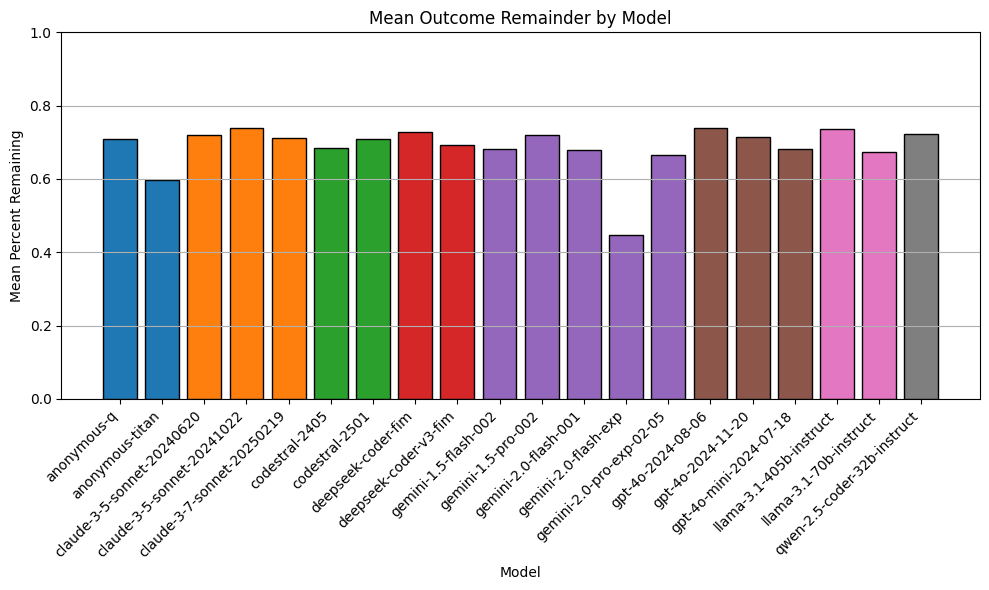

In [47]:
# Compute mean remainder per model
last_rows = get_trajectory_last_row(dataset_df)

mean_remainder_by_model = last_rows.groupby("model")["percent_remaining"].mean().reset_index()

models = mean_remainder_by_model["model"]
remainders = mean_remainder_by_model["percent_remaining"]

plt.figure(figsize=(10, 6))
# colors = plt.cm.tab10(np.linspace(0, 1, len(models)))
colors = [(0.12156862745098039, 0.4666666666666667, 0.7058823529411765, 1.0) for i in range(2)] + \
    [(1.0, 0.4980392156862745, 0.054901960784313725, 1.0) for i in range(3)] + \
    [(0.17254901960784313, 0.6274509803921569, 0.17254901960784313, 1.0) for i in range(2)] + \
    [(0.8392156862745098, 0.15294117647058825, 0.1568627450980392, 1.0) for i in range(2)] + \
    [(0.5803921568627451, 0.403921568627451, 0.7411764705882353, 1.0) for i in range(5)] + \
    [(0.5490196078431373, 0.33725490196078434, 0.29411764705882354, 1.0) for i in range(3)] + \
    [(0.8901960784313725, 0.4666666666666667, 0.7607843137254902, 1.0) for i in range(2)] + \
    [(0.4980392156862745, 0.4980392156862745, 0.4980392156862745, 1.0) for i in range(1)]
plt.bar(models, remainders, edgecolor='black', color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)  # since percent_remaining is between 0–1
plt.ylabel("Mean Percent Remaining")
plt.xlabel("Model")
plt.title("Mean Outcome Remainder by Model")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Average percent_remaining: 0.5554477023172044
Median percent_remaining: 0.6287683031869078


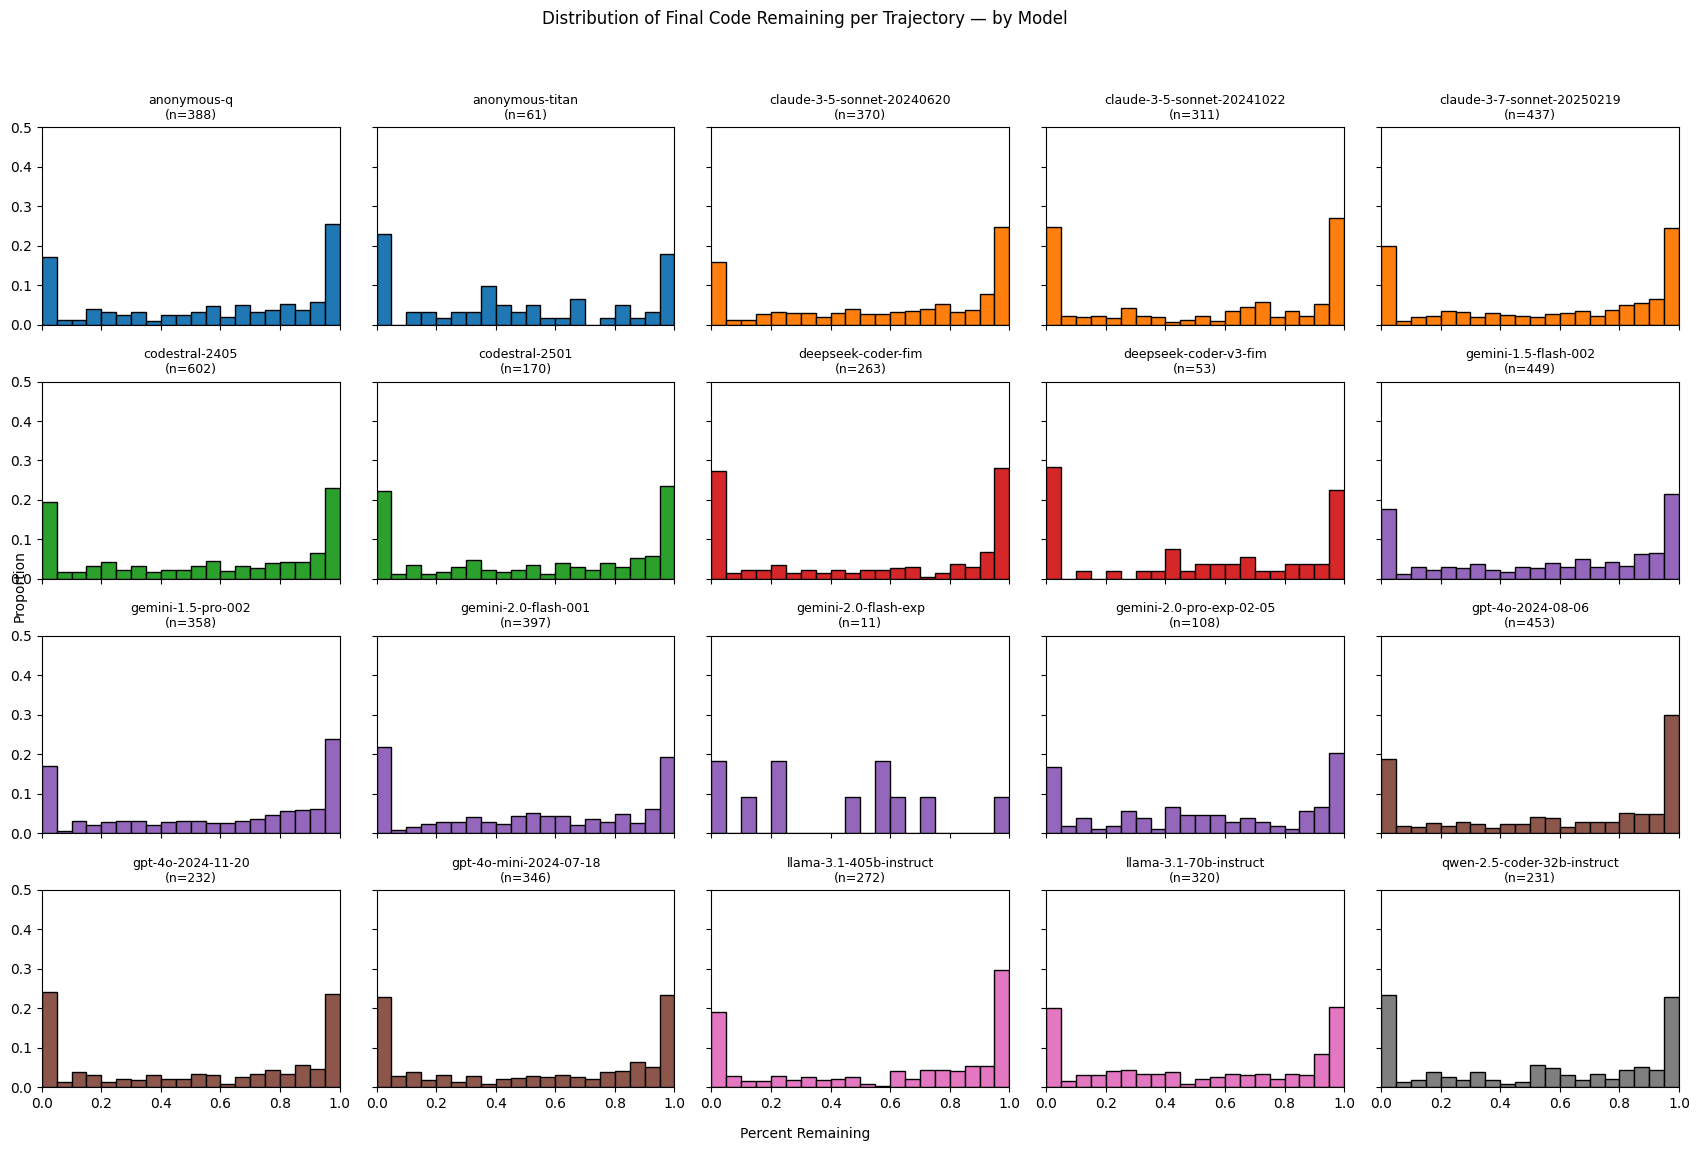

In [38]:
# Get last rows (one per trajectory)
last_rows = get_trajectory_last_row(dataset_df)

# Sort models for consistent layout
models = sorted(last_rows["model"].unique())

# Same color scheme as before
colors = (
    [(0.12156862745098039, 0.4666666666666667, 0.7058823529411765, 1.0) for i in range(2)] + 
    [(1.0, 0.4980392156862745, 0.054901960784313725, 1.0) for i in range(3)] + 
    [(0.17254901960784313, 0.6274509803921569, 0.17254901960784313, 1.0) for i in range(2)] + 
    [(0.8392156862745098, 0.15294117647058825, 0.1568627450980392, 1.0) for i in range(2)] + 
    [(0.5803921568627451, 0.403921568627451, 0.7411764705882353, 1.0) for i in range(5)] + 
    [(0.5490196078431373, 0.33725490196078434, 0.29411764705882354, 1.0) for i in range(3)] + 
    [(0.8901960784313725, 0.4666666666666667, 0.7607843137254902, 1.0) for i in range(2)] + 
    [(0.4980392156862745, 0.4980392156862745, 0.4980392156862745, 1.0) for i in range(1)]
)
colors = colors[:len(models)]

import numpy as np

# Common bins for consistent alignment
common_bins = np.linspace(0, 1, 21)

# 4x5 grid of histograms (shared x/y)
fig, axes = plt.subplots(4, 5, figsize=(18, 12), sharex=True, sharey=True)
axes = axes.ravel()

for i, model in enumerate(models):
    ax = axes[i]
    data = last_rows.loc[last_rows["model"] == model, "percent_remaining"].dropna()
    if len(data) == 0:
        ax.axis('off')
        continue
    weights = np.ones(len(data)) / len(data)  # each bin’s height = proportion
    ax.hist(data, bins=common_bins, weights=weights, edgecolor="black", color=colors[i])
    ax.set_title(f"{model}\n(n={len(data)})", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 0.5)  # cap y-axis at 0.5

# Hide unused axes if fewer than 20 models
for j in range(len(models), len(axes)):
    axes[j].axis('off')

# Common labels and title
fig.suptitle("Distribution of Final Code Remaining per Trajectory — by Model", y=0.98)
fig.text(0.5, 0.04, "Percent Remaining", ha="center")
fig.text(0.06, 0.5, "Proportion", va="center", rotation="vertical")

plt.tight_layout(rect=[0.05, 0.05, 1, 0.95])
plt.show()


In [ ]:
last_rows = get_trajectory_last_row(dataset_df)

def classify_model(name):
    name = name.lower()
    
    # Determine if open or closed source
    if any(x in name for x in ["anonymous", "claude", "gemini", "gpt"]):
        open_source = False
    elif any(x in name for x in ["codestral", "deepseek", "llama", "qwen"]):
        open_source = True
    else:
        open_source = None  # unknown / fallback
    
    # Determine if smaller variant
    smaller_model = any(x in name for x in ["flash", "mini", "70b"])
    
    # Determine family (optional, helps grouping later)
    family = None
    for fam in ["anonymous", "claude", "gemini", "gpt", "codestral", "deepseek", "llama", "qwen"]:
        if fam in name:
            family = fam.capitalize()
            break
    
    return pd.Series({
        "open_source": open_source,
        "smaller_model": smaller_model,
        "family": family
    })

# Apply classifier
meta = last_rows["model"].apply(classify_model)
last_rows = pd.concat([last_rows, meta], axis=1)

# Ensure correct dtypes
last_rows["open_source"] = last_rows["open_source"].astype(float)   # 1=open, 0=closed
last_rows["smaller_model"] = last_rows["smaller_model"].astype(float)
last_rows["family"] = last_rows["family"].astype("category")

# Drop rows with missing family/open_source annotations if needed
last_rows = last_rows.dropna(subset=["open_source", "family"])

model = smf.mixedlm(
    "percent_remaining ~ open_source + smaller_model",
    data=last_rows,
    groups=last_rows["model"]
).fit()
print(model.summary())

model = smf.mixedlm(
    "percent_remaining ~ family + smaller_model",
    data=last_rows,
    groups=last_rows["model"]
).fit()
print(model.summary())

In [40]:
model_stats = []

for model in dataset_df["model"].unique():
    model_df = dataset_df[dataset_df["model"] == model]

    def mean_remainder_within(minutes):
        cutoff = minutes * 60  # convert to seconds
        subset = model_df[model_df["time_since_completion"] <= cutoff]
        return subset["percent_remaining"].mean() if not subset.empty else 0

    mean_length = model_df.groupby("outcome_pair_id").size().mean()

    model_stats.append({
        "model": model,
        "mean_remainder_5min": mean_remainder_within(5),
        "mean_remainder_10min": mean_remainder_within(10),
        "mean_remainder_15min": mean_remainder_within(15),
        "mean_remainder_60min": mean_remainder_within(60),
        "mean_traj_length": mean_length,
        "count": len(model_df)
    })

model_stats_df = pd.DataFrame(model_stats)

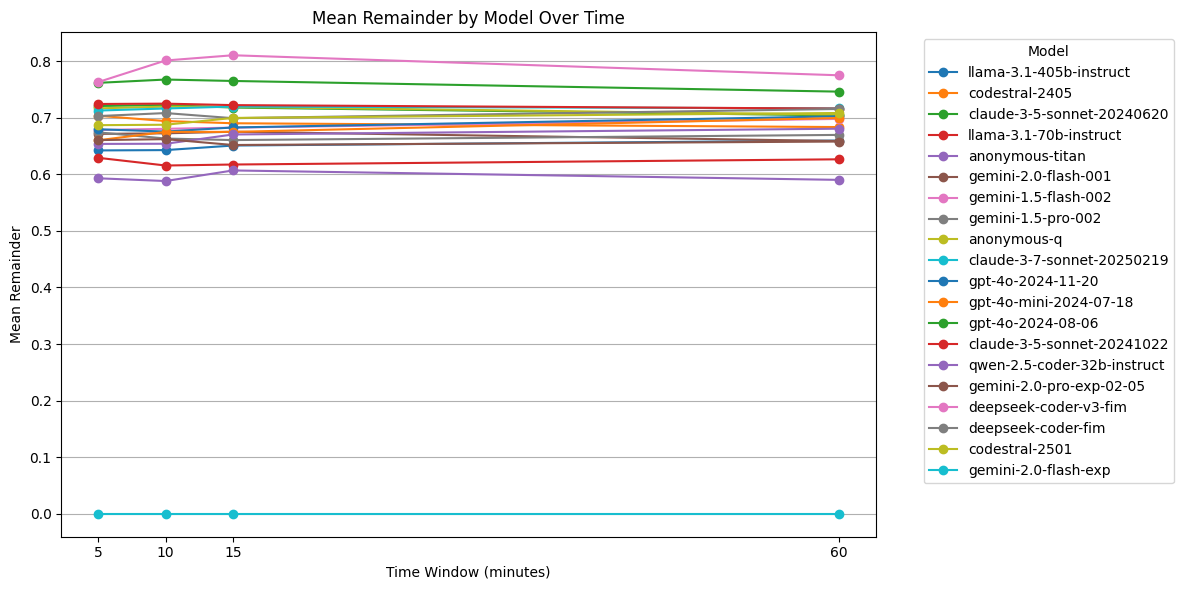

In [41]:
time_windows = [5, 10, 15, 60]  # in minutes
remainder_cols = ["mean_remainder_5min", "mean_remainder_10min", "mean_remainder_15min", "mean_remainder_60min"]

plt.figure(figsize=(12,6))

for idx, row in model_stats_df.iterrows():
    remainders = row[remainder_cols].values
    plt.plot(time_windows, remainders, marker='o', label=row["model"])

plt.xlabel("Time Window (minutes)")
plt.ylabel("Mean Remainder")
plt.title("Mean Remainder by Model Over Time")
plt.xticks(time_windows)
plt.grid(True, axis="y")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

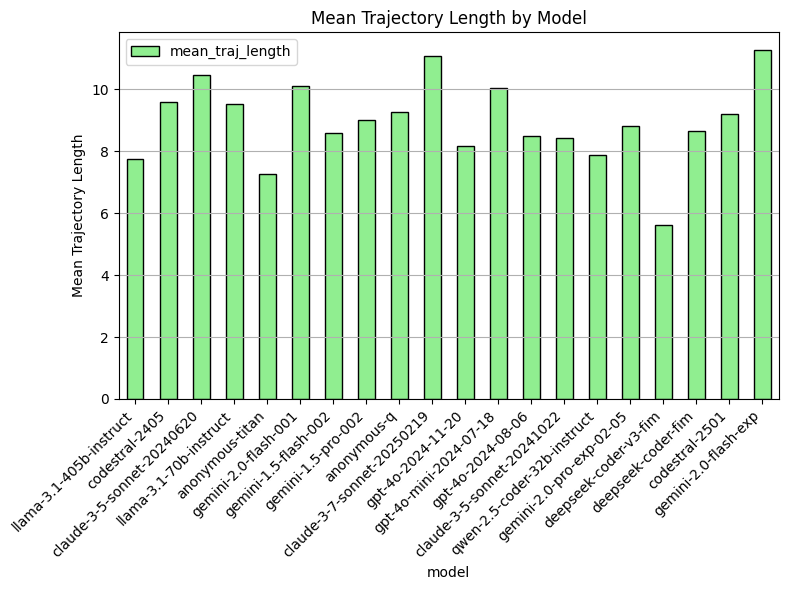

In [42]:
# Plot trajectory length separately
model_stats_df.set_index("model")[["mean_traj_length"]].plot(
    kind="bar", figsize=(8,6), color="lightgreen", edgecolor="black"
)
plt.ylabel("Mean Trajectory Length")
plt.title("Mean Trajectory Length by Model")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

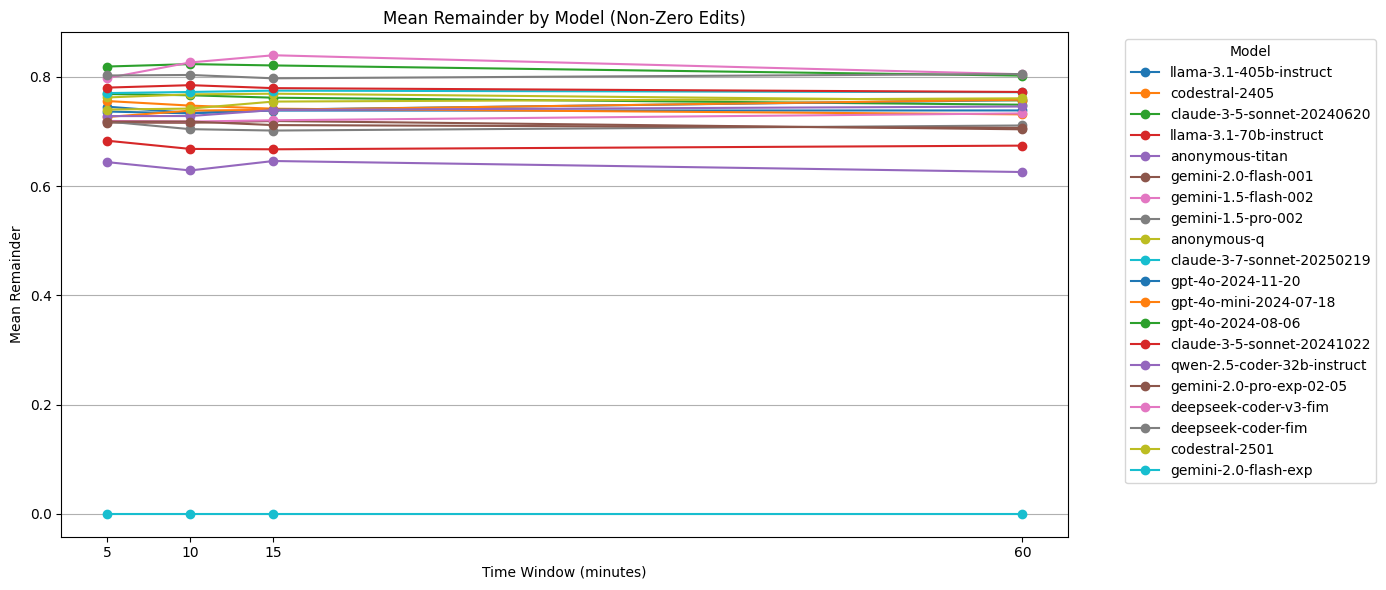

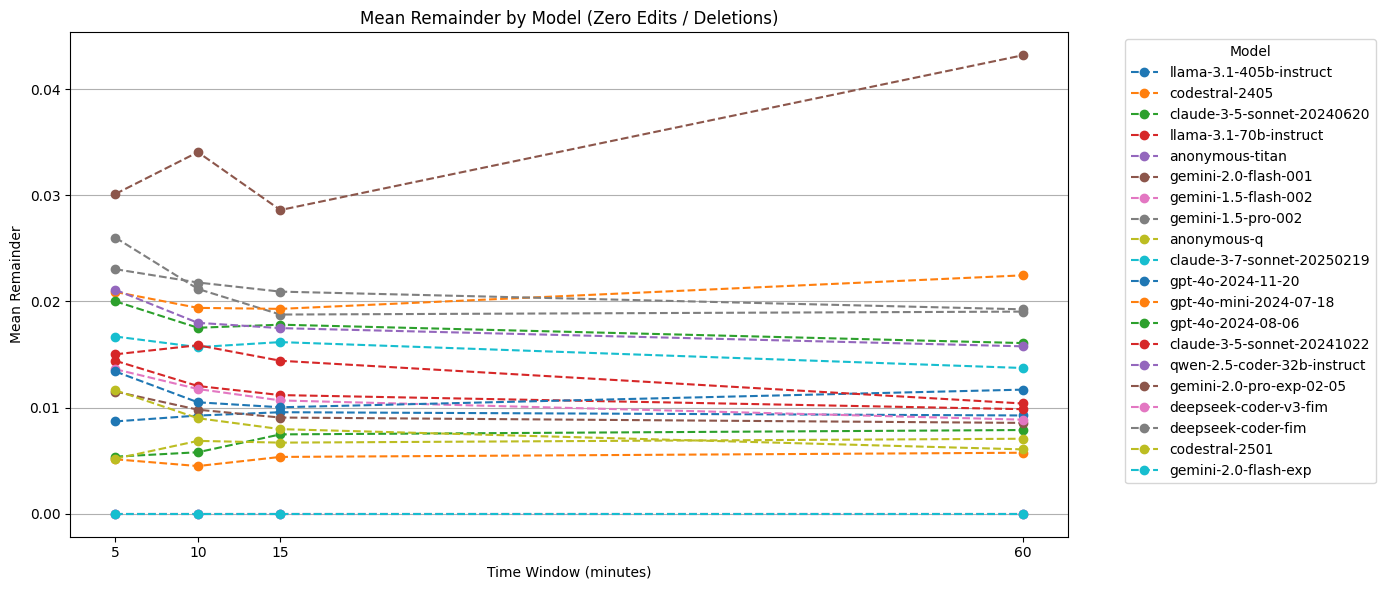

In [43]:
model_stats = []

for model in dataset_df["model"].unique():
    model_df = dataset_df[dataset_df["model"] == model]

    # Split into deletion vs non-deletion
    deletions = model_df[model_df["edit_full_snippet"].str.strip() == ""]
    non_deletions = model_df[model_df["edit_full_snippet"].str.strip() != ""]

    def mean_remainder_within(df, minutes):
        cutoff = minutes * 60
        subset = df[df["time_since_completion"] <= cutoff]
        return subset["percent_remaining"].mean() if not subset.empty else 0

    def collect_stats(df, label):
        return {
            "model": f"{model} ({label})",
            "mean_remainder_5min": mean_remainder_within(df, 5),
            "mean_remainder_10min": mean_remainder_within(df, 10),
            "mean_remainder_15min": mean_remainder_within(df, 15),
            "mean_remainder_60min": mean_remainder_within(df, 60),
            "mean_traj_length": df.groupby("outcome_pair_id").size().mean() if not df.empty else 0,
            "count": len(df)
        }

    model_stats.append(collect_stats(non_deletions, "no del"))
    model_stats.append(collect_stats(deletions, "del"))

model_stats_df = pd.DataFrame(model_stats)

time_windows = [5, 10, 15, 60]  # in minutes
remainder_cols = ["mean_remainder_5min", "mean_remainder_10min", "mean_remainder_15min", "mean_remainder_60min"]

# Separate dataframes
deletion_df = model_stats_df[model_stats_df["model"].str.endswith("(del)")]
non_deletion_df = model_stats_df[model_stats_df["model"].str.endswith("(no del)")]

# ---- Plot non-zero edits ----
plt.figure(figsize=(14,6))
for idx, row in non_deletion_df.iterrows():
    remainders = row[remainder_cols].values
    plt.plot(time_windows, remainders, marker='o', linestyle='-', label=row["model"].replace(" (no del)", ""))

plt.xlabel("Time Window (minutes)")
plt.ylabel("Mean Remainder")
plt.title("Mean Remainder by Model (Non-Zero Edits)")
plt.xticks(time_windows)
plt.grid(True, axis="y")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ---- Plot zero edits ----
plt.figure(figsize=(14,6))
for idx, row in deletion_df.iterrows():
    remainders = row[remainder_cols].values
    plt.plot(time_windows, remainders, marker='o', linestyle='--', label=row["model"].replace(" (del)", ""))

plt.xlabel("Time Window (minutes)")
plt.ylabel("Mean Remainder")
plt.title("Mean Remainder by Model (Zero Edits / Deletions)")
plt.xticks(time_windows)
plt.grid(True, axis="y")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

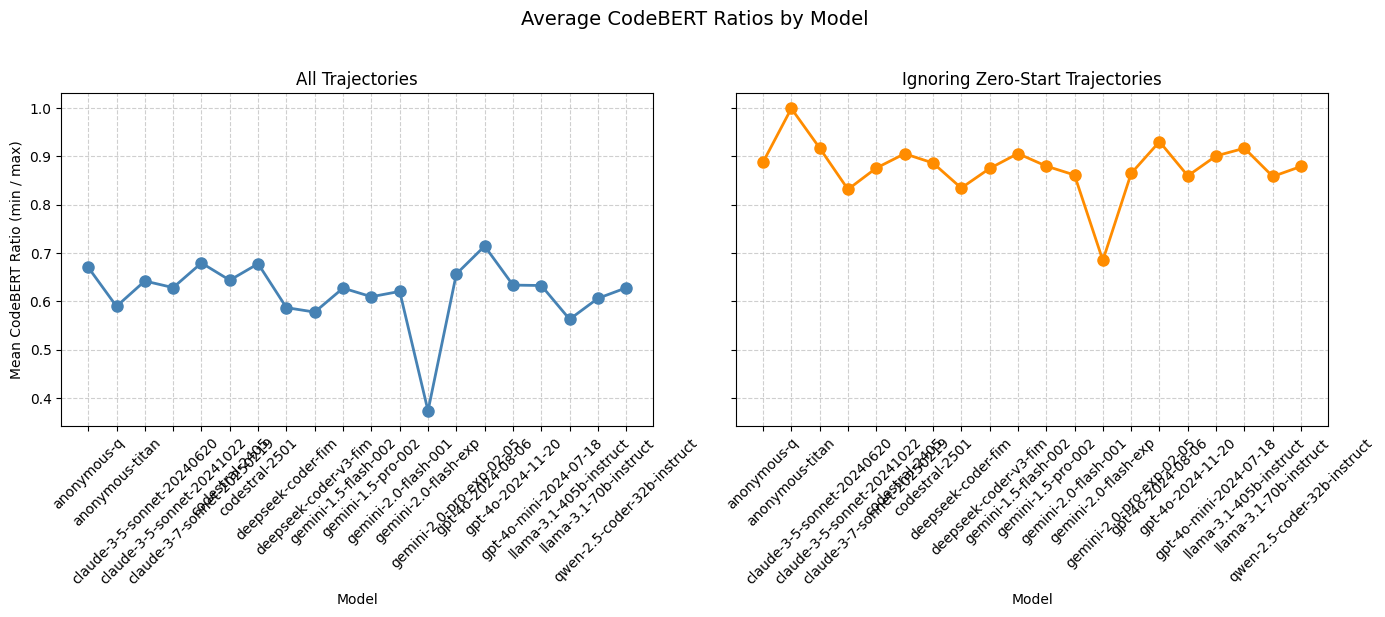

In [44]:
agg_df = (
    dataset_df.sort_values("edit_timestamp").groupby(["model", "outcome_completion_id"]).agg(
        min_timestamp=("edit_timestamp", "first"),
        max_timestamp=("edit_timestamp", "last"),
        min_codebert=("codebert_score", "first"),
        max_codebert=("codebert_score", "last"),
    )
    .reset_index()
)

agg_df["ratio"] = np.where(agg_df["max_codebert"] == 0, 0, agg_df["min_codebert"] / agg_df["max_codebert"])

mean_ratios_all = agg_df.groupby("model")["ratio"].mean()
filtered_df = agg_df[agg_df["min_codebert"] != 0]
mean_ratios_nonzero = filtered_df.groupby("model")["ratio"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].plot(
    mean_ratios_all.index,
    mean_ratios_all.values,
    marker="o",
    linestyle="-",
    color="steelblue",
    linewidth=2,
    markersize=8,
)
axes[0].set_title("All Trajectories")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Mean CodeBERT Ratio (min / max)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(
    mean_ratios_nonzero.index,
    mean_ratios_nonzero.values,
    marker="o",
    linestyle="-",
    color="darkorange",
    linewidth=2,
    markersize=8,
)
axes[1].set_title("Ignoring Zero-Start Trajectories")
axes[1].set_xlabel("Model")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, linestyle="--", alpha=0.6)

fig.suptitle("Average CodeBERT Ratios by Model", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

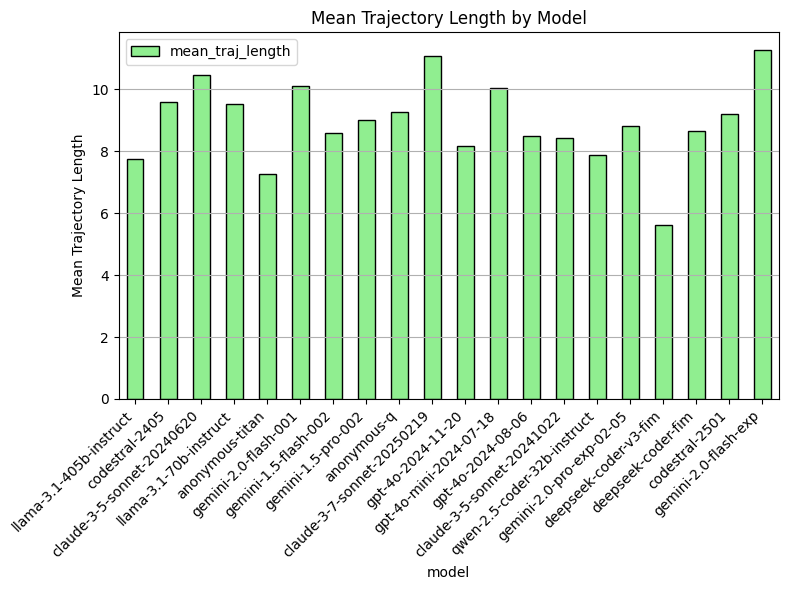

In [42]:
# Plot trajectory length separately
model_stats_df.set_index("model")[["mean_traj_length"]].plot(
    kind="bar", figsize=(8,6), color="lightgreen", edgecolor="black"
)
plt.ylabel("Mean Trajectory Length")
plt.title("Mean Trajectory Length by Model")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

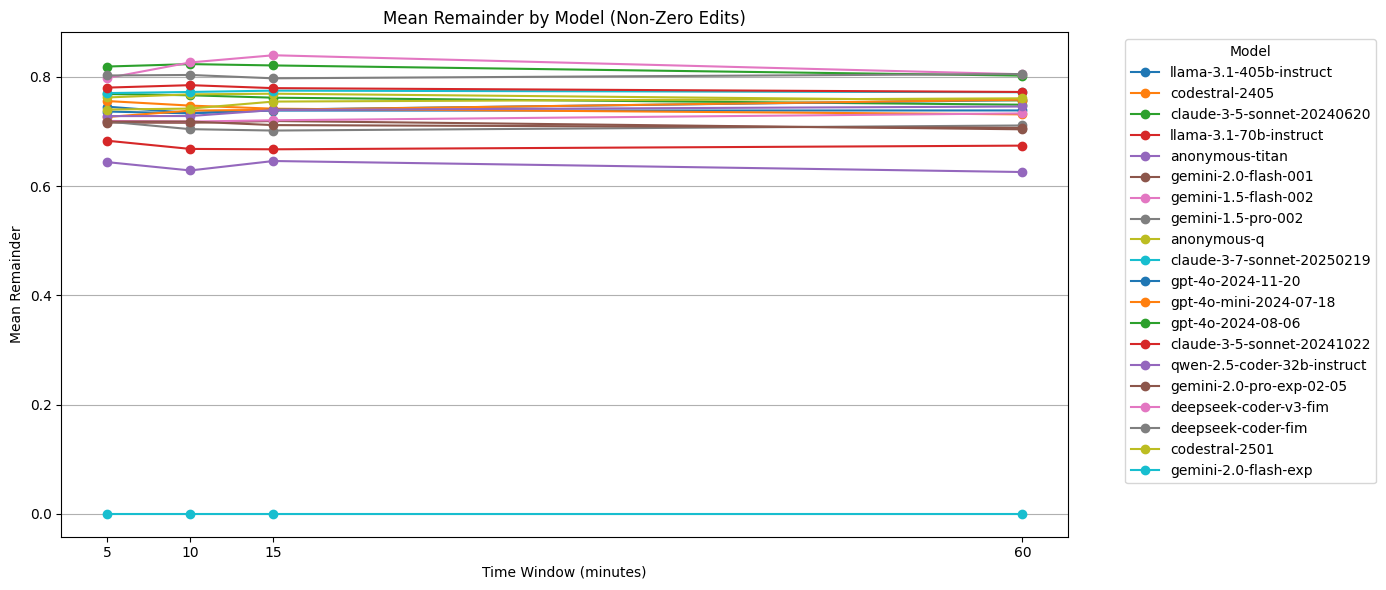

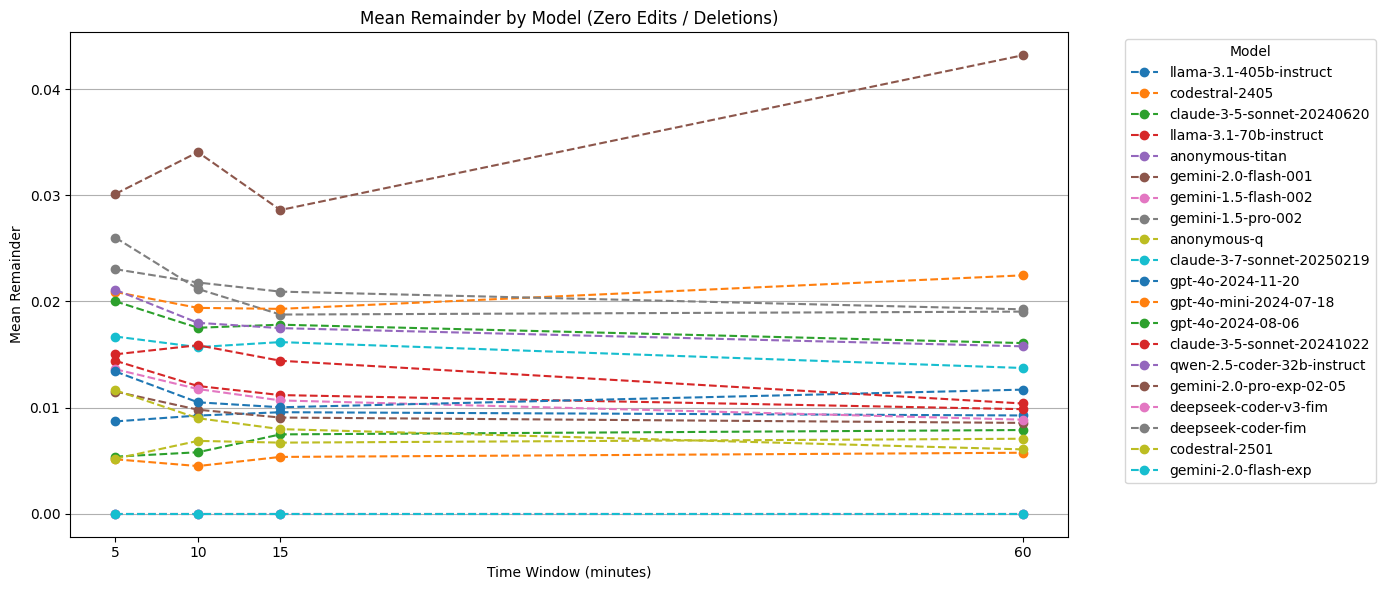

In [43]:
model_stats = []

for model in dataset_df["model"].unique():
    model_df = dataset_df[dataset_df["model"] == model]

    # Split into deletion vs non-deletion
    deletions = model_df[model_df["edit_full_snippet"].str.strip() == ""]
    non_deletions = model_df[model_df["edit_full_snippet"].str.strip() != ""]

    def mean_remainder_within(df, minutes):
        cutoff = minutes * 60
        subset = df[df["time_since_completion"] <= cutoff]
        return subset["percent_remaining"].mean() if not subset.empty else 0

    def collect_stats(df, label):
        return {
            "model": f"{model} ({label})",
            "mean_remainder_5min": mean_remainder_within(df, 5),
            "mean_remainder_10min": mean_remainder_within(df, 10),
            "mean_remainder_15min": mean_remainder_within(df, 15),
            "mean_remainder_60min": mean_remainder_within(df, 60),
            "mean_traj_length": df.groupby("outcome_pair_id").size().mean() if not df.empty else 0,
            "count": len(df)
        }

    model_stats.append(collect_stats(non_deletions, "no del"))
    model_stats.append(collect_stats(deletions, "del"))

model_stats_df = pd.DataFrame(model_stats)

time_windows = [5, 10, 15, 60]  # in minutes
remainder_cols = ["mean_remainder_5min", "mean_remainder_10min", "mean_remainder_15min", "mean_remainder_60min"]

# Separate dataframes
deletion_df = model_stats_df[model_stats_df["model"].str.endswith("(del)")]
non_deletion_df = model_stats_df[model_stats_df["model"].str.endswith("(no del)")]

# ---- Plot non-zero edits ----
plt.figure(figsize=(14,6))
for idx, row in non_deletion_df.iterrows():
    remainders = row[remainder_cols].values
    plt.plot(time_windows, remainders, marker='o', linestyle='-', label=row["model"].replace(" (no del)", ""))

plt.xlabel("Time Window (minutes)")
plt.ylabel("Mean Remainder")
plt.title("Mean Remainder by Model (Non-Zero Edits)")
plt.xticks(time_windows)
plt.grid(True, axis="y")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ---- Plot zero edits ----
plt.figure(figsize=(14,6))
for idx, row in deletion_df.iterrows():
    remainders = row[remainder_cols].values
    plt.plot(time_windows, remainders, marker='o', linestyle='--', label=row["model"].replace(" (del)", ""))

plt.xlabel("Time Window (minutes)")
plt.ylabel("Mean Remainder")
plt.title("Mean Remainder by Model (Zero Edits / Deletions)")
plt.xticks(time_windows)
plt.grid(True, axis="y")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

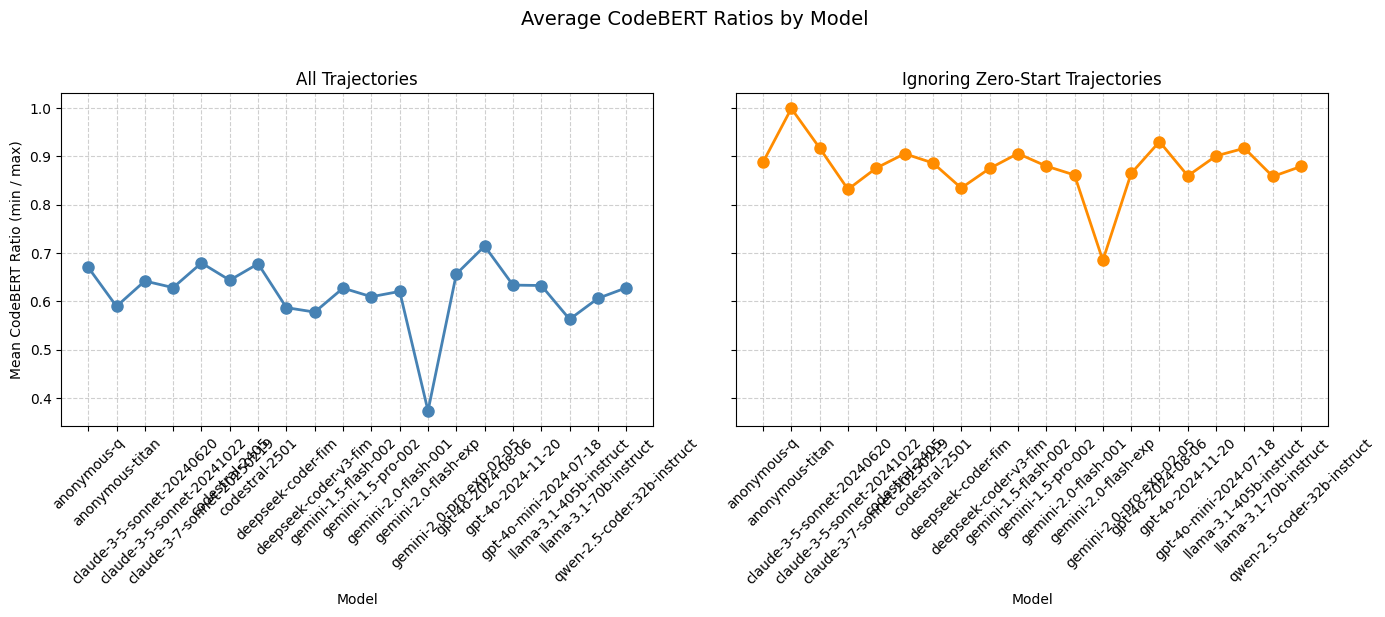

In [44]:
agg_df = (
    dataset_df.sort_values("edit_timestamp").groupby(["model", "outcome_completion_id"]).agg(
        min_timestamp=("edit_timestamp", "first"),
        max_timestamp=("edit_timestamp", "last"),
        min_codebert=("codebert_score", "first"),
        max_codebert=("codebert_score", "last"),
    )
    .reset_index()
)

agg_df["ratio"] = np.where(agg_df["max_codebert"] == 0, 0, agg_df["min_codebert"] / agg_df["max_codebert"])

mean_ratios_all = agg_df.groupby("model")["ratio"].mean()
filtered_df = agg_df[agg_df["min_codebert"] != 0]
mean_ratios_nonzero = filtered_df.groupby("model")["ratio"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].plot(
    mean_ratios_all.index,
    mean_ratios_all.values,
    marker="o",
    linestyle="-",
    color="steelblue",
    linewidth=2,
    markersize=8,
)
axes[0].set_title("All Trajectories")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Mean CodeBERT Ratio (min / max)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(
    mean_ratios_nonzero.index,
    mean_ratios_nonzero.values,
    marker="o",
    linestyle="-",
    color="darkorange",
    linewidth=2,
    markersize=8,
)
axes[1].set_title("Ignoring Zero-Start Trajectories")
axes[1].set_xlabel("Model")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, linestyle="--", alpha=0.6)

fig.suptitle("Average CodeBERT Ratios by Model", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Edit Labeling Analysis

In [3]:
# Load edits dataset
datasets = []
num_batches = 108
for i in range(num_batches):
    try:
        df = pd.read_csv(f"{data_folder}/dataset_with_edit_labels_{i}.csv")
        datasets.append(df)
    except:
        pass
dataset_df1 = pd.concat(datasets, ignore_index=True)

print("Dataset length:", len(dataset_df1))
print(dataset_df1.columns)
print(dataset_df1["llm_final_label"].unique())

Dataset length: 53343
Index(['Unnamed: 0', 'outcome_pair_completion_id', 'outcome_pair_id',
       'outcome_completion_id', 'outcome', 'outcome_snippet',
       'outcome_full_snippet', 'outcome_timestamp', 'outcome_full_file',
       'outcome_snippet_start_line', 'outcome_snippet_end_line',
       'edit_completion_id', 'edit_snippet', 'edit_full_file',
       'edit_timestamp', 'edit_full_snippet', 'all_changed_lines',
       'is_outcome', 'user_id', 'model', 'codebert_score',
       'outcome_context_and_removed_lines', 'edit_snippet_with_extra_context',
       'before_snippet', 'after_snippet', 'current_full_snippet',
       'current_snippet', 'llm_edit_labels', 'llm_final_label'],
      dtype='object')
['modifying-functionality' 'customizing-personalizing'
 'improving-code-quality' 'unchanged' 'start-over-commenting-out' nan]


In [4]:
num_trajectories = len(dataset_df1["outcome_completion_id"].unique())
print("Number of trajectories:", num_trajectories)

Number of trajectories: 5804


In [5]:
dataset_df1 = dataset_df1[dataset_df1['llm_final_label'] != 'unchanged']
dataset_df1 = dataset_df1.sort_values(['outcome_pair_id', 'edit_timestamp'])
dataset_df1['step_count'] = dataset_df1.groupby('outcome_pair_id').cumcount() + 1
# dataset_df1['steps_total'] = (dataset_df1.groupby('outcome_pair_id')['step_count'].transform('max'))
# dataset_df1['steps_percentile'] = dataset_df1.apply(lambda x: x['step_count'] / x['steps_total'], axis=1)

In [6]:
# Rename the "start-over-commenting-out" as "modifying-functionality"
# dataset_df1["llm_final_label_updated"] = dataset_df1["llm_final_label"].replace("start-over-commenting-out", "modifying-functionality")
dataset_df1["llm_final_label_updated"] = dataset_df1["llm_final_label"]

In [7]:
# Identify actual cases where there is commenting out as "start-over-commenting-out"
dataset_df1.loc[dataset_df1['edit_snippet'].isna(), 'llm_final_label_updated'] = "start-over-commenting-out"
print(dataset_df1["llm_final_label_updated"].unique())

['start-over-commenting-out' 'modifying-functionality'
 'improving-code-quality' 'customizing-personalizing' nan]


In [8]:
# Compute the number of seconds from completion
edit_ts = pd.to_numeric(dataset_df1['edit_timestamp'], errors='coerce')
outcome_ts = pd.to_numeric(dataset_df1['outcome_timestamp'], errors='coerce')
dataset_df1['time_from_completion'] = edit_ts - outcome_ts

In [9]:
start_over_df = dataset_df1[dataset_df1["llm_final_label_updated"] == 'start-over-commenting-out']
modifying_functionality_df = dataset_df1[dataset_df1["llm_final_label_updated"] == 'modifying-functionality']
improving_code_quality_df = dataset_df1[dataset_df1["llm_final_label_updated"] == 'improving-code-quality']
customizing_personalizing_df = dataset_df1[dataset_df1["llm_final_label_updated"] == 'customizing-personalizing']

In [75]:
contingency = dataset_df1.pivot_table(
    index='model',
    columns='llm_final_label_updated',
    aggfunc='size',
    fill_value=0
)

chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi2:", chi2)
print("p-value:", p)

residuals = (contingency - expected) / np.sqrt(expected)
print(residuals)

Chi2: 380.89591920889643
p-value: 1.95889880796058e-49
llm_final_label_updated      customizing-personalizing  \
model                                                    
anonymous-q                                   0.431864   
anonymous-titan                               8.292149   
claude-3-5-sonnet-20240620                    2.647043   
claude-3-5-sonnet-20241022                   -0.702408   
claude-3-7-sonnet-20250219                   -0.466344   
codestral-2405                               -1.411371   
codestral-2501                                1.037647   
deepseek-coder-fim                            4.778736   
deepseek-coder-v3-fim                         1.125058   
gemini-1.5-flash-002                         -0.399633   
gemini-1.5-pro-002                            0.749862   
gemini-2.0-flash-001                         -1.366789   
gemini-2.0-flash-exp                          3.636155   
gemini-2.0-pro-exp-02-05                     -0.198915   
gpt-4o-2024-08-06

array([[<Axes: title={'center': 'step_count'}>]], dtype=object)

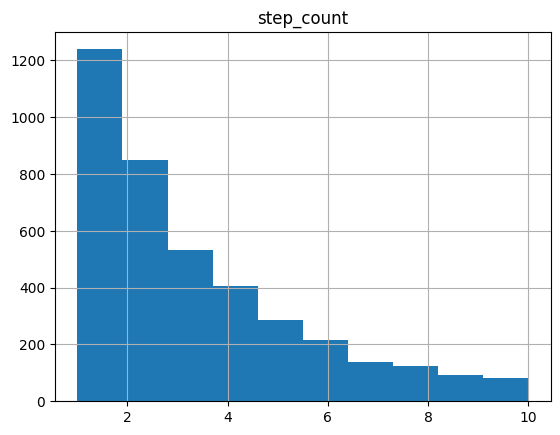

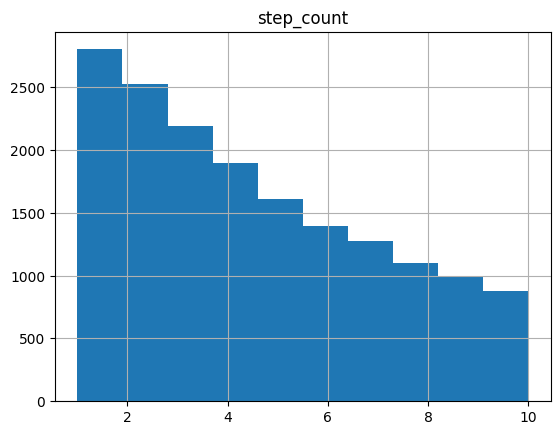

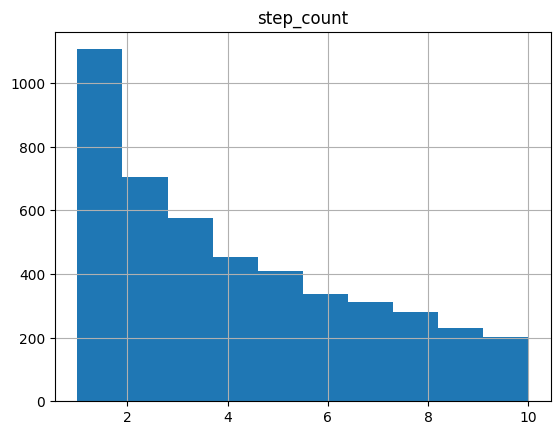

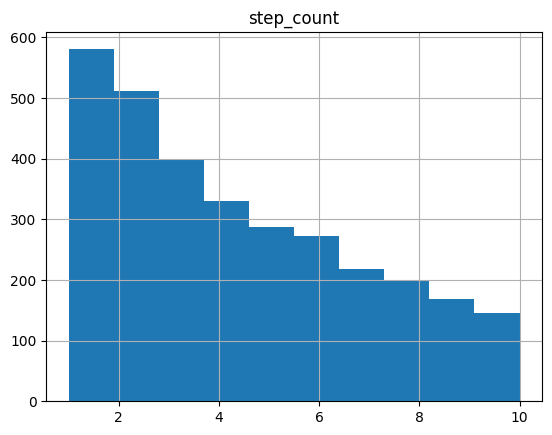

In [10]:
# The most common types of edits made in the first 10 edits
num_steps = 10
start_over_df[start_over_df['step_count'] <= num_steps].hist('step_count', bins=num_steps)
modifying_functionality_df[modifying_functionality_df['step_count'] <= num_steps].hist('step_count', bins=num_steps)
improving_code_quality_df[improving_code_quality_df['step_count'] <= num_steps].hist('step_count', bins=num_steps)
customizing_personalizing_df[customizing_personalizing_df['step_count'] <= num_steps].hist('step_count', bins=num_steps)

In [12]:
# The number of snapshots with various labels
start_over_count = len(start_over_df)
modifying_functionality_count = len(modifying_functionality_df)
improving_code_quality_count = len(improving_code_quality_df)
customizing_personalizing_count = len(customizing_personalizing_df)

print('start-over-commenting-out', '\t', start_over_count, '\t', start_over_count / len(dataset_df1))
print('modifying-functionality', '\t', modifying_functionality_count, '\t', modifying_functionality_count / len(dataset_df1))
print('improving-code-quality', '\t\t', improving_code_quality_count, '\t', improving_code_quality_count / len(dataset_df1))
print('customizing-personalizing', '\t', customizing_personalizing_count, '\t', customizing_personalizing_count / len(dataset_df1))

start-over-commenting-out 	 4572 	 0.09701033334040612
modifying-functionality 	 29606 	 0.6281907106028135
improving-code-quality 		 7301 	 0.15491523265929683
customizing-personalizing 	 5152 	 0.1093169810520062


In [20]:
modifying_functionality_lines = []
improving_code_quality_lines = []
customizing_personalizing_lines = []

for idx, row in dataset_df1.iterrows():
    raw = row.get("llm_edit_labels", None)
    
    if pd.isna(raw):
        continue
    
    try:
        parsed_lines = json.loads(raw)

        estimated_length = 0
        for l in parsed_lines:
            estimated_length += len(l)

        estimated_current_index = 0
        for i, l in enumerate(parsed_lines):
            estimated_current_index += len(l)
            if l['label'] == 'modifying-functionality':
                modifying_functionality_lines.append(estimated_current_index / estimated_length)
            elif l['label'] == 'customizing-personalizing':
                customizing_personalizing_lines.append(estimated_current_index / estimated_length)
            elif l['label'] == 'improving-code-quality':
                improving_code_quality_lines.append(estimated_current_index / estimated_length)
    except (json.JSONDecodeError, TypeError):
        # skip rows that aren't valid JSON
        continue

median_modifying = np.median(modifying_functionality_lines)
median_improving = np.median(improving_code_quality_lines)
median_customizing = np.median(customizing_personalizing_lines)

print("Modifying functionality median:", median_modifying, len(modifying_functionality_lines))
print("Improving code quality median:", median_improving, len(improving_code_quality_lines))
print("Customizing/personalizing median:", median_customizing, len(customizing_personalizing_lines))

Modifying functionality median: 0.6585365853658537 98191
Improving code quality median: 0.569490434142752 35406
Customizing/personalizing median: 0.6666666666666666 10581


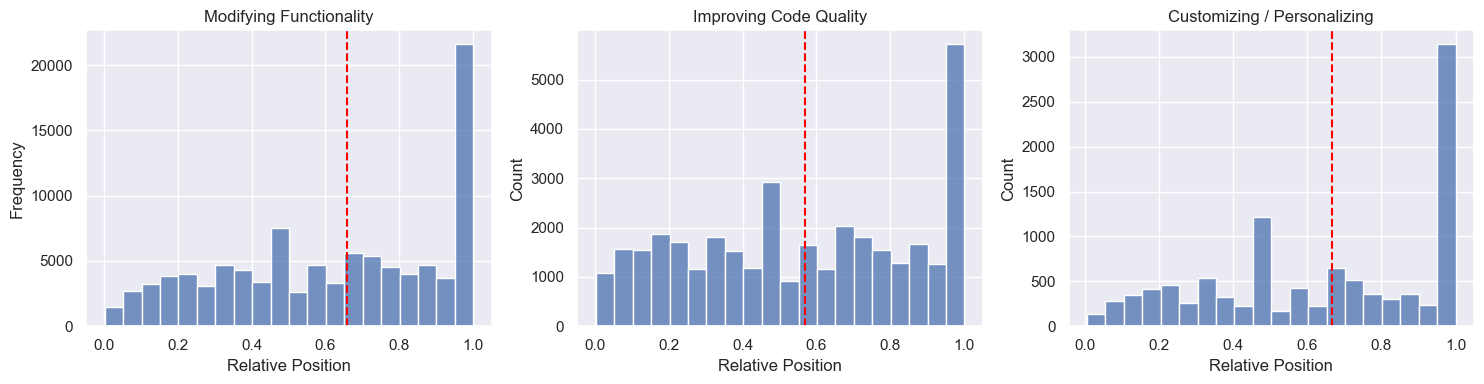

In [23]:
sns.set_theme()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Modifying functionality
sns.histplot(modifying_functionality_lines, bins=20, ax=axes[0])
axes[0].axvline(median_modifying, color="red", linestyle="--")
axes[0].set_title("Modifying Functionality")
axes[0].set_xlabel("Relative Position")
axes[0].set_ylabel("Frequency")

# Improving code quality
sns.histplot(improving_code_quality_lines, bins=20, ax=axes[1])
axes[1].axvline(median_improving, color="red", linestyle="--")
axes[1].set_title("Improving Code Quality")
axes[1].set_xlabel("Relative Position")

# Customizing/personalizing
sns.histplot(customizing_personalizing_lines, bins=20, ax=axes[2])
axes[2].axvline(median_customizing, color="red", linestyle="--")
axes[2].set_title("Customizing / Personalizing")
axes[2].set_xlabel("Relative Position")

plt.tight_layout()
plt.show()

In [56]:
# The number of trajectories with various labels
start_over_trajectory_count = dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "start-over-commenting-out").any()).sum()
modifying_functionality_trajectory_count = dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "modifying-functionality").any()).sum()
improving_code_trajectory_count = dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "improving-code-quality").any()).sum()
customizing_personalizing_trajectory_count = dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "customizing-personalizing").any()).sum()

print('start-over-commenting-out', '\t', start_over_trajectory_count, '\t', start_over_trajectory_count / num_trajectories)
print('modifying-functionality', '\t', modifying_functionality_trajectory_count, '\t', modifying_functionality_trajectory_count / num_trajectories)
print('improving-code-quality', '\t\t', improving_code_trajectory_count, '\t', improving_code_trajectory_count / num_trajectories)
print('customizing-personalizing', '\t', customizing_personalizing_trajectory_count, '\t', customizing_personalizing_trajectory_count / num_trajectories)

start-over-commenting-out 	 2867 	 0.49168238724061053
modifying-functionality 	 4480 	 0.7683073229291717
improving-code-quality 		 2788 	 0.478134110787172
customizing-personalizing 	 2042 	 0.35019722174584117


In [38]:
# The number of trajectories with various labels
filtered_dataset_df1 = dataset_df1[dataset_df1["time_from_completion"] <= 60 * 15]
filtered_num_trajectories = filtered_dataset_df1["outcome_pair_id"].nunique()

start_over_trajectory_count = filtered_dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "start-over-commenting-out").any()).sum()
modifying_functionality_trajectory_count = filtered_dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "modifying-functionality").any()).sum()
improving_code_trajectory_count = filtered_dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "improving-code-quality").any()).sum()
customizing_personalizing_trajectory_count = filtered_dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].apply(lambda x: (x == "customizing-personalizing").any()).sum()

print('start-over-commenting-out', '\t', start_over_trajectory_count, '\t', start_over_trajectory_count / filtered_num_trajectories)
print('modifying-functionality', '\t', modifying_functionality_trajectory_count, '\t', modifying_functionality_trajectory_count / filtered_num_trajectories)
print('improving-code-quality', '\t\t', improving_code_trajectory_count, '\t', improving_code_trajectory_count / filtered_num_trajectories)
print('customizing-personalizing', '\t', customizing_personalizing_trajectory_count, '\t', customizing_personalizing_trajectory_count / filtered_num_trajectories)

start-over-commenting-out 	 1515 	 0.30643203883495146
modifying-functionality 	 3521 	 0.7121763754045307
improving-code-quality 		 1972 	 0.3988673139158576
customizing-personalizing 	 1254 	 0.2536407766990291


In [15]:
# Average position of each type of edit
print('start-over-commenting-out', '\t', start_over_df['step_count'].median())
print('modifying-functionality', '\t', modifying_functionality_df['step_count'].median())
print('improving-code-quality', '\t\t', improving_code_quality_df['step_count'].median())
print('customizing-personalizing', '\t', customizing_personalizing_df['step_count'].median())

start-over-commenting-out 	 2.0
modifying-functionality 	 9.0
improving-code-quality 		 7.0
customizing-personalizing 	 8.0


In [22]:
# Average duration from the start of the edit
print('start-over-commenting-out', '\t', start_over_df['time_from_completion'].median(), 'seconds')
print('modifying-functionality', '\t', modifying_functionality_df['time_from_completion'].median(), 'seconds')
print('improving-code-quality', '\t\t', improving_code_quality_df['time_from_completion'].median(), 'seconds')
print('customizing-personalizing', '\t', customizing_personalizing_df['time_from_completion'].median(), 'seconds')

start-over-commenting-out 	 1418.0 seconds
modifying-functionality 	 3550.5 seconds
improving-code-quality 		 1695.0 seconds
customizing-personalizing 	 2957.0 seconds


In [48]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

start_over_times = start_over_df['time_from_completion']
modifying_funtionality_times = modifying_functionality_df['time_from_completion']
improving_code_quality_times = improving_code_quality_df['time_from_completion']
customizing_personalizing_times = customizing_personalizing_df['time_from_completion']

groups = {
    "start_over": start_over_times,
    "modifying_functionality": modifying_funtionality_times,
    "improving_code_quality": improving_code_quality_times,
    "customizing_personalizing": customizing_personalizing_times
}

pairs = list(combinations(groups.keys(), 2))

results = []
p_values = []

# Run all pairwise tests
for g1, g2 in pairs:
    x = groups[g1]
    y = groups[g2]
    
    stat, p = mannwhitneyu(x, y, alternative='two-sided')
    
    results.append({
        "group1": g1,
        "group2": g2,
        "U_stat": stat,
        "p_raw": p
    })
    
    p_values.append(p)

# Apply Bonferroni correction via statsmodels
reject, p_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Attach corrected results
for i in range(len(results)):
    results[i]["corrected"] = p_corrected[i]
    results[i]["reject_null"] = reject[i]

results_df = pd.DataFrame(results).sort_values("corrected")

print(results_df)

                    group1                     group2       U_stat  \
3  modifying_functionality     improving_code_quality  120844548.5   
0               start_over    modifying_functionality   59423649.0   
2               start_over  customizing_personalizing   10793930.0   
5   improving_code_quality  customizing_personalizing   17322622.5   
4  modifying_functionality  customizing_personalizing   79281540.5   
1               start_over     improving_code_quality   16574437.0   

          p_raw     corrected  reject_null  
3  2.878965e-55  1.727379e-54         True  
0  1.668413e-50  5.005240e-50         True  
2  3.908900e-17  7.817799e-17         True  
5  5.704090e-14  8.556135e-14         True  
4  5.674571e-06  6.809486e-06         True  
1  3.410968e-02  3.410968e-02         True  


In [11]:
start_over_times = start_over_df['time_from_completion']
modifying_functionality_times = modifying_functionality_df['time_from_completion']
improving_code_quality_times = improving_code_quality_df['time_from_completion']
customizing_personalizing_times = customizing_personalizing_df['time_from_completion']

# Kruskal-Wallis test across all groups
stat, p = kruskal(
    start_over_times,
    modifying_functionality_times,
    improving_code_quality_times,
    customizing_personalizing_times
)

results_df = pd.DataFrame([{
    "test": "Kruskal-Wallis",
    "groups_compared": 4,
    "H_stat": stat,
    "p_value": p,
    "reject_null": p < 0.05
}])

print(results_df)

             test  groups_compared      H_stat       p_value  reject_null
0  Kruskal-Wallis                4  394.548613  3.356944e-85         True


<Axes: >

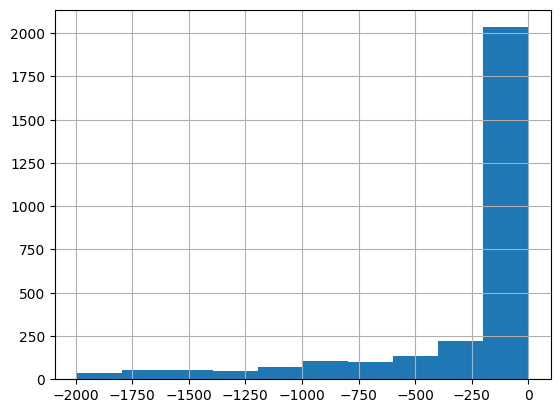

In [45]:
# Plot the distribution of when the types of edits occur after the start of the completion
time_threshold = -2000
start_over_df[start_over_df['time_from_completion'] > time_threshold]['time_from_completion'].hist()

<Axes: >

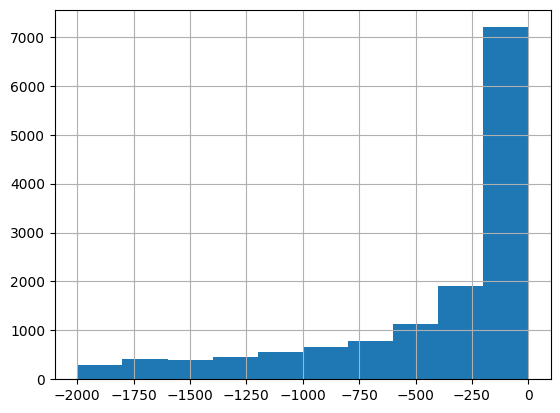

In [46]:
modifying_functionality_df[modifying_functionality_df['time_from_completion'] > time_threshold]['time_from_completion'].hist()

<Axes: >

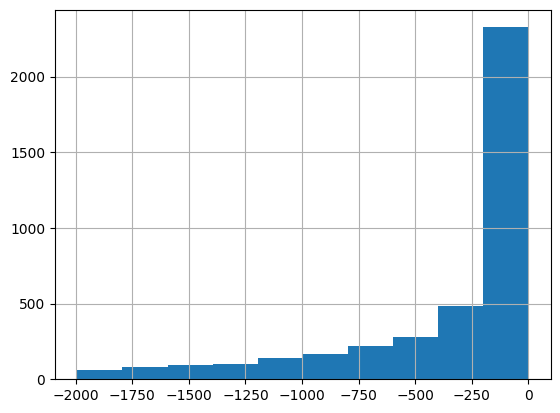

In [47]:
improving_code_quality_df[improving_code_quality_df['time_from_completion'] > time_threshold]['time_from_completion'].hist()

<Axes: >

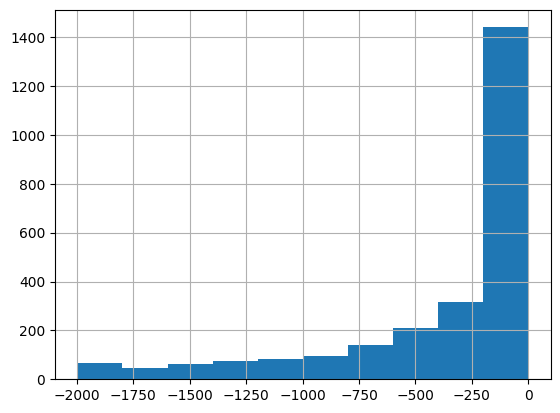

In [48]:
customizing_personalizing_df[customizing_personalizing_df['time_from_completion'] > time_threshold]['time_from_completion'].hist()

In [26]:
# What edit type occurs first
def get_step_edit_types(step_number):
    nth_edit_df = dataset_df1[dataset_df1['step_count'] == step_number]
    
    start_over_trajectory_count = len(nth_edit_df[nth_edit_df['llm_final_label_updated'] == 'start-over-commenting-out'])
    modifying_functionality_trajectory_count = len(nth_edit_df[nth_edit_df['llm_final_label_updated'] == 'modifying-functionality'])
    improving_code_trajectory_count = len(nth_edit_df[nth_edit_df['llm_final_label_updated'] == 'improving-code-quality'])
    customizing_personalizing_trajectory_count = len(nth_edit_df[nth_edit_df['llm_final_label_updated'] == 'customizing-personalizing'])

    print('step', step_number)
    print('start-over-commenting-out', start_over_trajectory_count, start_over_trajectory_count / num_trajectories)
    print('modifying-functionality', modifying_functionality_trajectory_count, modifying_functionality_trajectory_count / num_trajectories)
    print('improving-code-quality', improving_code_trajectory_count, improving_code_trajectory_count / num_trajectories)
    print('customizing-personalizing', customizing_personalizing_trajectory_count, customizing_personalizing_trajectory_count / num_trajectories)
    print()

get_step_edit_types(1)
get_step_edit_types(2)
get_step_edit_types(3)
get_step_edit_types(4)
get_step_edit_types(5)

step 1
start-over-commenting-out 1241 0.21381805651274982
modifying-functionality 2781 0.4791523087525844
improving-code-quality 1097 0.18900758097863543
customizing-personalizing 574 0.0988973121984838

step 2
start-over-commenting-out 808 0.13921433494141972
modifying-functionality 2277 0.392315644383184
improving-code-quality 646 0.11130254996554101
customizing-personalizing 474 0.08166781529979325

step 3
start-over-commenting-out 515 0.08873190902825638
modifying-functionality 2066 0.3559614059269469
improving-code-quality 527 0.09079944865609924
customizing-personalizing 377 0.06495520330806341

step 4
start-over-commenting-out 368 0.06340454858718125
modifying-functionality 1807 0.3113370089593384
improving-code-quality 440 0.07580978635423846
customizing-personalizing 300 0.051688490696071676

step 5
start-over-commenting-out 292 0.05031013094417643
modifying-functionality 1527 0.26309441764300484
improving-code-quality 386 0.06650585802894556
customizing-personalizing 278 0.04

In [13]:
def compute_transition_percentages(x):
    if x['label_transition'].startswith('modifying-functionality'):
        return x['count'] / modifying_functionality_count
    elif x['label_transition'].startswith('improving-code-quality'):
        return x['count'] / improving_code_quality_count
    elif x['label_transition'].startswith('customizing-personalizing'):
        return x['count'] / customizing_personalizing_count
    elif x['label_transition'].startswith('start-over-commenting-out'):
        return x['count'] / start_over_count
    else:
        return np.nan

# Caluclate the frequencies of each transition
dataset_df1['previous_edit_type'] = (dataset_df1.groupby('outcome_completion_id')['llm_final_label_updated'].shift(1).fillna(''))
dataset_df1['label_transition'] = (dataset_df1['previous_edit_type'] + ['_' for _ in range(len(dataset_df1))] + dataset_df1['llm_final_label_updated'])

transition_counts_df = dataset_df1['label_transition'].value_counts().reset_index()
transition_counts_df.columns = ['label_transition', 'count']
transition_counts_df['percentage'] = transition_counts_df.apply(compute_transition_percentages, axis=1)
transition_counts_df['before_state'] = transition_counts_df['label_transition'].str.split('_').str[0]
transition_counts_df['after_state'] = transition_counts_df['label_transition'].str.split('_').str[1]
transition_counts_df = transition_counts_df.sort_values("label_transition")
transition_counts_df

,label_transition,count,percentage,before_state,after_state
13,_customizing-personalizing,580,NaN,,customizing-personalizing
12,_improving-code-quality,1106,NaN,,improving-code-quality
3,_modifying-functionality,2801,NaN,,modifying-functionality
11,_start-over-commenting-out,1238,NaN,,start-over-commenting-out
8,customizing-personalizing_customizing-personal...,1461,0.283579,customizing-personalizing,customizing-personalizing
14,customizing-personalizing_improving-code-quality,567,0.110054,customizing-personalizing,improving-code-quality
5,customizing-personalizing_modifying-functionality,2262,0.439053,customizing-personalizing,modifying-functionality
17,customizing-personalizing_start-over-commentin...,252,0.048913,customizing-personalizing,start-over-commenting-out
15,improving-code-quality_customizing-personalizing,478,0.065470,improving-code-quality,customizing-personalizing
6,improving-code-quality_improving-code-quality,1835,0.251335,improving-code-quality,improving-code-quality


<Axes: xlabel='after_state', ylabel='before_state'>

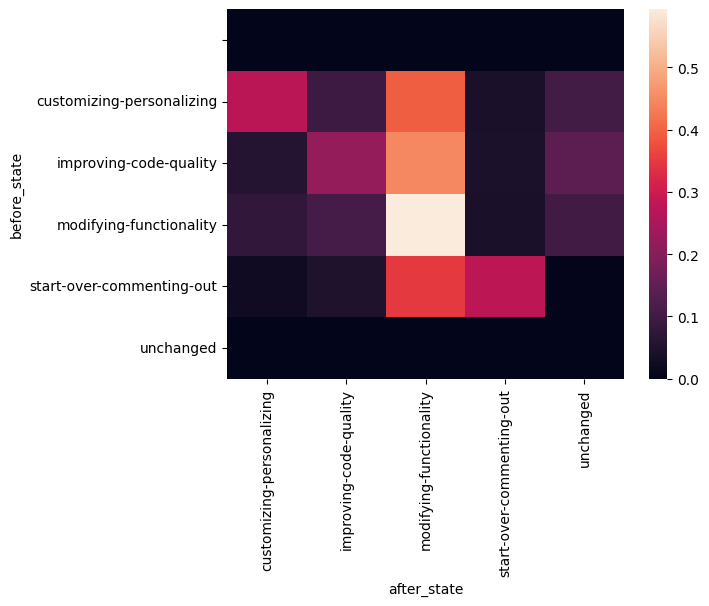

In [28]:
# Visualize the transitions as a heatmap
transition_matrix = transition_counts_df.pivot_table(
    index='before_state',
    columns='after_state',
    values='percentage',
    aggfunc='sum',
    fill_value=0
)
sns.heatmap(transition_matrix)

In [31]:
# Compute the transitions for start-over-commenting-out
start_over_transitions_df = dataset_df1[dataset_df1['previous_edit_type'] == 'start-over-commenting-out']
start_over_transitions_df = start_over_transitions_df[start_over_transitions_df['step_count'] == 2]
start_over_transitions_df = start_over_transitions_df[start_over_transitions_df['llm_final_label_updated'] != 'unchanged']

start_over_transition_count = len(start_over_transitions_df[start_over_transitions_df['llm_final_label_updated'] == 'start-over-commenting-out'])
modifying_functionality_transition_count = len(start_over_transitions_df[start_over_transitions_df['llm_final_label_updated'] == 'modifying-functionality'])
improving_code_quality_transition_count = len(start_over_transitions_df[start_over_transitions_df['llm_final_label_updated'] == 'improving-code-quality'])
customizing_personalizing_transition_count = len(start_over_transitions_df[start_over_transitions_df['llm_final_label_updated'] == 'customizing-personalizing'])

num_transitions = start_over_transition_count + modifying_functionality_transition_count + improving_code_quality_transition_count + customizing_personalizing_transition_count

print('start-over-commenting-out', start_over_transition_count, start_over_transition_count / num_transitions)
print('modifying-functionality', modifying_functionality_transition_count, modifying_functionality_transition_count / num_transitions)
print('improving-code-quality', improving_code_quality_transition_count, improving_code_quality_transition_count / num_transitions)
print('customizing-personalizing', customizing_personalizing_transition_count, customizing_personalizing_transition_count / num_transitions)

start-over-commenting-out 392 0.46335697399527187
modifying-functionality 341 0.4030732860520095
improving-code-quality 65 0.0768321513002364
customizing-personalizing 48 0.05673758865248227


In [32]:
# Compute the transitions for modifying-functionality
modifying_functionality_transitions_df = dataset_df1[dataset_df1['previous_edit_type'] == 'modifying-functionality']
modifying_functionality_transitions_df = modifying_functionality_transitions_df[modifying_functionality_transitions_df['step_count'] == 2]
modifying_functionality_transitions_df = modifying_functionality_transitions_df[modifying_functionality_transitions_df['llm_final_label_updated'] != 'unchanged']

start_over_transition_count = len(modifying_functionality_transitions_df[modifying_functionality_transitions_df['llm_final_label_updated'] == 'start-over-commenting-out'])
modifying_functionality_transition_count = len(modifying_functionality_transitions_df[modifying_functionality_transitions_df['llm_final_label_updated'] == 'modifying-functionality'])
improving_code_quality_transition_count = len(modifying_functionality_transitions_df[modifying_functionality_transitions_df['llm_final_label_updated'] == 'improving-code-quality'])
customizing_personalizing_transition_count = len(modifying_functionality_transitions_df[modifying_functionality_transitions_df['llm_final_label_updated'] == 'customizing-personalizing'])

num_transitions = start_over_transition_count + modifying_functionality_transition_count + improving_code_quality_transition_count + customizing_personalizing_transition_count

print('start-over-commenting-out', start_over_transition_count, start_over_transition_count / num_transitions)
print('modifying-functionality', modifying_functionality_transition_count, modifying_functionality_transition_count / num_transitions)
print('improving-code-quality', improving_code_quality_transition_count, improving_code_quality_transition_count / num_transitions)
print('customizing-personalizing', customizing_personalizing_transition_count, customizing_personalizing_transition_count / num_transitions)

start-over-commenting-out 259 0.1215962441314554
modifying-functionality 1343 0.6305164319248826
improving-code-quality 318 0.14929577464788732
customizing-personalizing 210 0.09859154929577464


In [33]:
# Compute the transitions for improving-code-quality
improving_code_quality_transitions_df = dataset_df1[dataset_df1['previous_edit_type'] == 'improving-code-quality']
improving_code_quality_transitions_df = improving_code_quality_transitions_df[improving_code_quality_transitions_df['step_count'] == 2]
improving_code_quality_transitions_df = improving_code_quality_transitions_df[improving_code_quality_transitions_df['llm_final_label_updated'] != 'unchanged']

start_over_transition_count = len(improving_code_quality_transitions_df[improving_code_quality_transitions_df['llm_final_label_updated'] == 'start-over-commenting-out'])
modifying_functionality_transition_count = len(improving_code_quality_transitions_df[improving_code_quality_transitions_df['llm_final_label_updated'] == 'modifying-functionality'])
improving_code_quality_transition_count = len(improving_code_quality_transitions_df[improving_code_quality_transitions_df['llm_final_label_updated'] == 'improving-code-quality'])
customizing_personalizing_transition_count = len(improving_code_quality_transitions_df[improving_code_quality_transitions_df['llm_final_label_updated'] == 'customizing-personalizing'])

num_transitions = start_over_transition_count + modifying_functionality_transition_count + improving_code_quality_transition_count + customizing_personalizing_transition_count

print('start-over-commenting-out', start_over_transition_count, start_over_transition_count / num_transitions)
print('modifying-functionality', modifying_functionality_transition_count, modifying_functionality_transition_count / num_transitions)
print('improving-code-quality', improving_code_quality_transition_count, improving_code_quality_transition_count / num_transitions)
print('customizing-personalizing', customizing_personalizing_transition_count, customizing_personalizing_transition_count / num_transitions)

start-over-commenting-out 108 0.14007782101167315
modifying-functionality 381 0.49416342412451364
improving-code-quality 205 0.26588845654993515
customizing-personalizing 77 0.09987029831387809


In [34]:
# Compute the transitions for customizing-personalizing
customizing_personalizing_quality_transitions_df = dataset_df[dataset_df['previous_edit_type'] == 'customizing-personalizing']
customizing_personalizing_quality_transitions_df = customizing_personalizing_quality_transitions_df[customizing_personalizing_quality_transitions_df['step_count'] == 2]
customizing_personalizing_quality_transitions_df = customizing_personalizing_quality_transitions_df[customizing_personalizing_quality_transitions_df['llm_final_label_updated'] != 'unchanged']

start_over_transition_count = len(customizing_personalizing_quality_transitions_df[customizing_personalizing_quality_transitions_df['llm_final_label_updated'] == 'start-over-commenting-out'])
modifying_functionality_transition_count = len(customizing_personalizing_quality_transitions_df[customizing_personalizing_quality_transitions_df['llm_final_label_updated'] == 'modifying-functionality'])
improving_code_quality_transition_count = len(customizing_personalizing_quality_transitions_df[customizing_personalizing_quality_transitions_df['llm_final_label_updated'] == 'improving-code-quality'])
customizing_personalizing_transition_count = len(customizing_personalizing_quality_transitions_df[customizing_personalizing_quality_transitions_df['llm_final_label_updated'] == 'customizing-personalizing'])

num_transitions = start_over_transition_count + modifying_functionality_transition_count + improving_code_quality_transition_count + customizing_personalizing_transition_count

print('start-over-commenting-out', start_over_transition_count, start_over_transition_count / num_transitions)
print('modifying-functionality', modifying_functionality_transition_count, modifying_functionality_transition_count / num_transitions)
print('improving-code-quality', improving_code_quality_transition_count, improving_code_quality_transition_count / num_transitions)
print('customizing-personalizing', customizing_personalizing_transition_count, customizing_personalizing_transition_count / num_transitions)

start-over-commenting-out 44 0.10377358490566038
modifying-functionality 194 0.45754716981132076
improving-code-quality 50 0.1179245283018868
customizing-personalizing 136 0.32075471698113206


In [21]:
classification_data = [
    {"edits": 0, "model": "Qwen2.5-3B (FT)", "value": 0.42},
    {"edits": 1, "model": "Qwen2.5-3B (FT)", "value": 0.50},
    {"edits": 2, "model": "Qwen2.5-3B (FT)", "value": 0.50},
    {"edits": 3, "model": "Qwen2.5-3B (FT)", "value": 0.50},
    {"edits": 4, "model": "Qwen2.5-3B (FT)", "value": 0.51},
    
    {"edits": 0, "model": "Qwen2.5-3B (base)", "value": 0.19},
    {"edits": 1, "model": "Qwen2.5-3B (base)", "value": 0.22},
    {"edits": 2, "model": "Qwen2.5-3B (base)", "value": 0.21},
    {"edits": 3, "model": "Qwen2.5-3B (base)", "value": 0.21},
    {"edits": 4, "model": "Qwen2.5-3B (base)", "value": 0.21},
    
    {"edits": 0, "model": "Qwen2.5-7B (FT)", "value": 0.45},
    {"edits": 1, "model": "Qwen2.5-7B (FT)", "value": 0.49},
    {"edits": 2, "model": "Qwen2.5-7B (FT)", "value": 0.51},
    {"edits": 3, "model": "Qwen2.5-7B (FT)", "value": 0.41},
    {"edits": 4, "model": "Qwen2.5-7B (FT)", "value": 0.49},
    
    {"edits": 0, "model": "Qwen2.5-7B (base)", "value": 0.21},
    {"edits": 1, "model": "Qwen2.5-7B (base)", "value": 0.23},
    {"edits": 2, "model": "Qwen2.5-7B (base)", "value": 0.23},
    {"edits": 3, "model": "Qwen2.5-7B (base)", "value": 0.23},
    {"edits": 4, "model": "Qwen2.5-7B (base)", "value": 0.23},
    
    {"edits": 0, "model": "Llama-3.2-3B (FT)", "value": 0.44},
    {"edits": 1, "model": "Llama-3.2-3B (FT)", "value": 0.43},
    {"edits": 2, "model": "Llama-3.2-3B (FT)", "value": 0.49},
    {"edits": 3, "model": "Llama-3.2-3B (FT)", "value": 0.50},
    {"edits": 4, "model": "Llama-3.2-3B (FT)", "value": 0.49},
    
    {"edits": 0, "model": "Llama-3.2-3B (base)", "value": 0.23},
    {"edits": 1, "model": "Llama-3.2-3B (base)", "value": 0.26},
    {"edits": 2, "model": "Llama-3.2-3B (base)", "value": 0.27},
    {"edits": 3, "model": "Llama-3.2-3B (base)", "value": 0.28},
    {"edits": 4, "model": "Llama-3.2-3B (base)", "value": 0.28},
]

### Analysis of Amount of Edit Trajectory Data Provided

<Figure size 600x500 with 0 Axes>

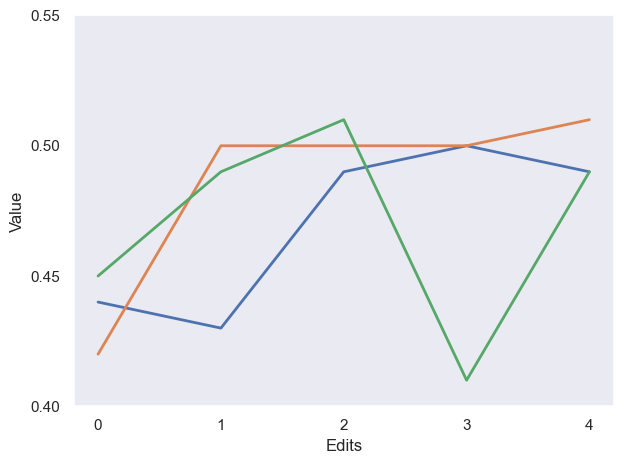

In [71]:
sns.set_theme()  # removes grid

my_df = pd.DataFrame(classification_data)

plt.figure(figsize=(6, 5))

# Assign one color per model family (ignore FT/base)
base_models = sorted({m.split(" (")[0] for m in my_df["model"]})

# Try color map but with sns.color_palette()'s colors
palette = sns.color_palette("deep", n_colors=len(base_models))
color_map = dict(zip(base_models, palette))

fig, ax = plt.subplots()

for model, group in my_df.groupby("model"):
    base_name = model.split(" (")[0]
    color = color_map[base_name]
    linestyle = "-" if "(FT)" in model else "--"

    if linestyle == "-":
        
        ax.plot(
            group["edits"],
            group["value"],
            linestyle=linestyle,
            color=color,
            linewidth=2
        )

ax.set_xlabel("Edits")
ax.set_ylabel("Value")

# Use MaxNLocator
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.set_yticks([0.4, 0.45, 0.50, 0.55])
ax.set_ylim(0.4, 0.55)

plt.tight_layout()
plt.grid(False)
plt.show()

In [22]:
generation_data = [
    {"edits": 0, "model": "Qwen2.5-3B (FT)", "value": 0.41}, 
    {"edits": 1, "model": "Qwen2.5-3B (FT)", "value": 0.44}, 
    {"edits": 2, "model": "Qwen2.5-3B (FT)", "value": 0.45}, 
    {"edits": 3, "model": "Qwen2.5-3B (FT)", "value": 0.50}, 
    {"edits": 4, "model": "Qwen2.5-3B (FT)", "value": 0.52}, 
    
    {"edits": 0, "model": "Qwen2.5-3B (base)", "value": 0.26}, 
    {"edits": 1, "model": "Qwen2.5-3B (base)", "value": 0.24}, 
    {"edits": 2, "model": "Qwen2.5-3B (base)", "value": 0.31}, 
    {"edits": 3, "model": "Qwen2.5-3B (base)", "value": 0.31}, 
    {"edits": 4, "model": "Qwen2.5-3B (base)", "value": 0.33}, 
    
    {"edits": 0, "model": "Qwen2.5-7B (FT)", "value": 0.43}, 
    {"edits": 1, "model": "Qwen2.5-7B (FT)", "value": 0.44}, 
    {"edits": 2, "model": "Qwen2.5-7B (FT)", "value": 0.46}, 
    {"edits": 3, "model": "Qwen2.5-7B (FT)", "value": 0.49}, 
    {"edits": 4, "model": "Qwen2.5-7B (FT)", "value": 0.52}, 
    
    {"edits": 0, "model": "Qwen2.5-7B (base)", "value": 0.30}, 
    {"edits": 1, "model": "Qwen2.5-7B (base)", "value": 0.31}, 
    {"edits": 2, "model": "Qwen2.5-7B (base)", "value": 0.38}, 
    {"edits": 3, "model": "Qwen2.5-7B (base)", "value": 0.40}, 
    {"edits": 4, "model": "Qwen2.5-7B (base)", "value": 0.41}, 
    
    {"edits": 0, "model": "Llama-3.2-3B (FT)", "value": 0.43}, 
    {"edits": 1, "model": "Llama-3.2-3B (FT)", "value": 0.45}, 
    {"edits": 2, "model": "Llama-3.2-3B (FT)", "value": 0.48}, 
    {"edits": 3, "model": "Llama-3.2-3B (FT)", "value": 0.50}, 
    {"edits": 4, "model": "Llama-3.2-3B (FT)", "value": 0.52}, 
    
    {"edits": 0, "model": "Llama-3.2-3B (base)", "value": 0.21}, 
    {"edits": 1, "model": "Llama-3.2-3B (base)", "value": 0.23}, 
    {"edits": 2, "model": "Llama-3.2-3B (base)", "value": 0.30}, 
    {"edits": 3, "model": "Llama-3.2-3B (base)", "value": 0.31}, 
    {"edits": 4, "model": "Llama-3.2-3B (base)", "value": 0.32},
]

<Figure size 600x500 with 0 Axes>

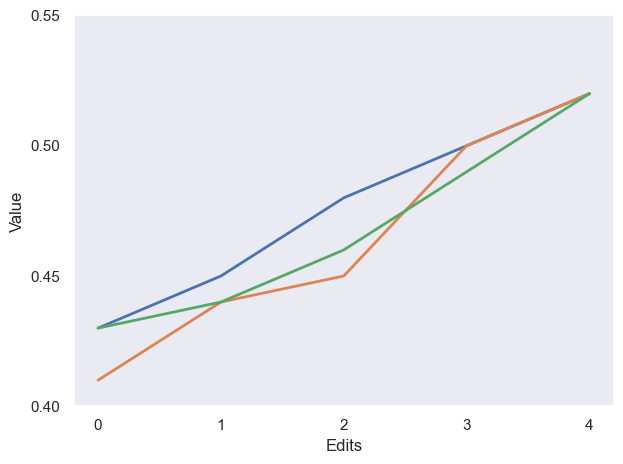

In [70]:
sns.set_theme()  # removes grid

my_df = pd.DataFrame(generation_data)

plt.figure(figsize=(6, 5))

# Assign one color per model family (ignore FT/base)
base_models = sorted({m.split(" (")[0] for m in my_df["model"]})

# Try color map but with sns.color_palette()'s colors
palette = sns.color_palette("deep", n_colors=len(base_models))
color_map = dict(zip(base_models, palette))

fig, ax = plt.subplots()

for model, group in my_df.groupby("model"):
    base_name = model.split(" (")[0]
    color = color_map[base_name]
    linestyle = "-" if "(FT)" in model else "--"

    if linestyle == "-":
        ax.plot(
            group["edits"],
            group["value"],
            linestyle=linestyle,
            color=color,
            linewidth=2
        )

ax.set_xlabel("Edits")
ax.set_ylabel("Value")

# Use MaxNLocator
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.set_yticks([0.4, 0.45, 0.50, 0.55])
ax.set_ylim(0.4, 0.55)

plt.tight_layout()
plt.grid(False)
plt.show()